# Customer Intelligence ML Platform

This single Kaggle notebook covers the current project workflow:

1. Load and validate the UCI credit-card client dataset.
2. Audit data quality and undocumented codes.
3. Create a fixed, stratified train/test split.
4. Perform exploratory analysis using training data.
5. Compare leakage-safe preprocessing strategies.
6. Fit and interpret PCA without using the target.
7. Evaluate K-Means segmentation and DBSCAN anomaly exploration.
8. Audit split diversity and train a feature-engineered gradient-boosting classifier.
9. Calibrate the classifier and export deployment artifacts.

Dataset: [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)  
License: CC BY 4.0  
Citation: Yeh, I. (2009). DOI: [10.24432/C55S3H](https://doi.org/10.24432/C55S3H)

This is an educational project. It must not be used to make real credit decisions.

## 1. Kaggle setup

Enable Internet access in Kaggle notebook settings. A GPU session may be enabled, but the scikit-learn estimators in this notebook run on CPU so their artifacts remain portable to FastAPI and Vercel.

In [17]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("ucimlrepo") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "ucimlrepo==0.0.7"]
    )

print("ucimlrepo is ready.")

ucimlrepo is ready.


In [18]:
import json
import sklearn
from time import perf_counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    adjusted_rand_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    calinski_harabasz_score,
    confusion_matrix,
    davies_bouldin_score,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TRAIN_SIZE = 0.80
VALIDATION_SIZE = 0.10
TEST_SIZE = 0.10
UCI_DATASET_ID = 350

## 2. Load and validate the official dataset

The target remains separate from the features. It will not be used to fit preprocessing, PCA, K-Means, or DBSCAN.

In [19]:
raw_feature_names = [f"X{index}" for index in range(1, 24)]
semantic_feature_names = [
    "credit_limit",
    "sex",
    "education",
    "marriage",
    "age",
    "repayment_status_sep",
    "repayment_status_aug",
    "repayment_status_jul",
    "repayment_status_jun",
    "repayment_status_may",
    "repayment_status_apr",
    "bill_statement_sep",
    "bill_statement_aug",
    "bill_statement_jul",
    "bill_statement_jun",
    "bill_statement_may",
    "bill_statement_apr",
    "previous_payment_sep",
    "previous_payment_aug",
    "previous_payment_jul",
    "previous_payment_jun",
    "previous_payment_may",
    "previous_payment_apr",
]
FEATURE_NAME_MAP = dict(zip(raw_feature_names, semantic_feature_names))

credit_default = fetch_ucirepo(id=UCI_DATASET_ID)
X_raw = credit_default.data.features.copy()
y_raw = credit_default.data.targets.copy()
ids = credit_default.data.ids.copy() if credit_default.data.ids is not None else None

assert list(X_raw.columns) == raw_feature_names, "Unexpected feature columns."
X = X_raw.rename(columns=FEATURE_NAME_MAP).reset_index(drop=True)
y = pd.to_numeric(y_raw.iloc[:, 0], errors="raise").astype("int8")
y = y.rename("default_next_month").reset_index(drop=True)
ids = ids.reset_index(drop=True) if ids is not None else None

assert X.shape == (30_000, 23), f"Unexpected feature shape: {X.shape}"
assert y.shape == (30_000,), f"Unexpected target shape: {y.shape}"
assert int(X.isna().sum().sum()) == 0, "Features contain missing values."
assert int(y.isna().sum()) == 0, "Target contains missing values."
assert set(y.unique()) == {0, 1}, "Unexpected target values."
assert ids is not None, "Expected identifier column is missing."
assert int(ids.duplicated().sum()) == 0, "Identifiers are not unique."

print("All dataset validation checks passed.")

All dataset validation checks passed.


In [20]:
validation_summary = pd.Series(
    {
        "rows": len(X),
        "features": X.shape[1],
        "missing feature values": int(X.isna().sum().sum()),
        "missing target values": int(y.isna().sum()),
        "duplicate identifiers": int(ids.duplicated().sum()),
        "class 0 records": int((y == 0).sum()),
        "class 1 records": int((y == 1).sum()),
        "historical default rate": f"{y.mean():.2%}",
    },
    name="value",
)
display(validation_summary.to_frame())

,value
rows,30000
features,23
missing feature values,0
missing target values,0
duplicate identifiers,0
class 0 records,23364
class 1 records,6636
historical default rate,22.12%


## 3. Audit data quality and category codes

Exact duplicate feature profiles are reported but not automatically removed because different customers can share recorded values. Codes not covered by the current UCI description are called undocumented, not invalid.

In [21]:
quality_summary = pd.Series(
    {
        "duplicate feature profiles": int(X.duplicated().sum()),
        "duplicate feature and target rows": int(
            pd.concat([X, y], axis=1).duplicated().sum()
        ),
        "minimum bill balance": int(
            X.filter(like="bill_statement_").min().min()
        ),
        "maximum bill balance": int(
            X.filter(like="bill_statement_").max().max()
        ),
        "maximum previous payment": int(
            X.filter(like="previous_payment_").max().max()
        ),
    },
    name="value",
)
display(quality_summary.to_frame())

,value
duplicate feature profiles,56
duplicate feature and target rows,35
minimum bill balance,-339603
maximum bill balance,1664089
maximum previous payment,1684259


In [22]:
DOCUMENTED_CODES = {
    "sex": {1, 2},
    "education": {1, 2, 3, 4},
    "marriage": {1, 2, 3},
}
REPAYMENT_FEATURES = [column for column in X if column.startswith("repayment_status_")]
for column in REPAYMENT_FEATURES:
    DOCUMENTED_CODES[column] = {-1, 1, 2, 3, 4, 5, 6, 7, 8, 9}

audit_rows = []
for column, documented_codes in DOCUMENTED_CODES.items():
    observed_codes = set(int(value) for value in X[column].unique())
    audit_rows.append(
        {
            "feature": column,
            "observed codes": sorted(observed_codes),
            "observed but undocumented": sorted(observed_codes - documented_codes),
            "documented but not observed": sorted(documented_codes - observed_codes),
        }
    )

category_audit = pd.DataFrame(audit_rows).set_index("feature")
display(category_audit)

,observed codes,observed but undocumented,documented but not observed
feature,,,
sex,"[1, 2]",[],[]
education,"[0, 1, 2, 3, 4, 5, 6]","[0, 5, 6]",[]
marriage,"[0, 1, 2, 3]",[0],[]
repayment_status_sep,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",[9]
repayment_status_aug,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",[9]
repayment_status_jul,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",[9]
repayment_status_jun,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",[9]
repayment_status_may,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]","[1, 9]"
repayment_status_apr,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]","[1, 9]"


In [23]:
category_count_frames = []
for column in ["sex", "education", "marriage"]:
    counts = X[column].value_counts().sort_index().rename("count").to_frame()
    counts["percentage"] = counts["count"] / len(X)
    counts.insert(0, "feature", column)
    counts.insert(1, "code", counts.index)
    category_count_frames.append(counts.reset_index(drop=True))

demographic_code_counts = pd.concat(category_count_frames, ignore_index=True)
display(
    demographic_code_counts.style.format({"percentage": "{:.2%}"})
)

,feature,code,count,percentage
0,sex,1,11888,39.63%
1,sex,2,18112,60.37%
2,education,0,14,0.05%
3,education,1,10585,35.28%
4,education,2,14030,46.77%
5,education,3,4917,16.39%
6,education,4,123,0.41%
7,education,5,280,0.93%
8,education,6,51,0.17%
9,marriage,0,54,0.18%


## 4. Create the fixed supervised holdout split

The dataset is shuffled and target-stratified into 80% training, 10% validation, and 10% test partitions. The validation and test partitions are isolated before target-guided exploration or fitted preprocessing.

In [24]:
assert np.isclose(TRAIN_SIZE + VALIDATION_SIZE + TEST_SIZE, 1.0)
all_indices = np.arange(len(X))
development_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    shuffle=True,
    random_state=RANDOM_STATE,
    stratify=y,
)
validation_share_of_development = VALIDATION_SIZE / (
    TRAIN_SIZE + VALIDATION_SIZE
)
train_indices, validation_indices = train_test_split(
    development_indices,
    test_size=validation_share_of_development,
    shuffle=True,
    random_state=RANDOM_STATE,
    stratify=y.iloc[development_indices],
)

X_train = X.iloc[train_indices].reset_index(drop=True)
X_validation = X.iloc[validation_indices].reset_index(drop=True)
X_test = X.iloc[test_indices].reset_index(drop=True)
y_train = y.iloc[train_indices].reset_index(drop=True)
y_validation = y.iloc[validation_indices].reset_index(drop=True)
y_test = y.iloc[test_indices].reset_index(drop=True)
X_development = X.iloc[development_indices].reset_index(drop=True)
y_development = y.iloc[development_indices].reset_index(drop=True)

split_manifest = ids.copy()
split_manifest["split"] = "training"
split_manifest.loc[validation_indices, "split"] = "validation"
split_manifest.loc[test_indices, "split"] = "test"

output_directory = Path("/kaggle/working")
if not output_directory.exists():
    output_directory = Path.cwd() / "ml" / "artifacts"
output_directory.mkdir(parents=True, exist_ok=True)
split_manifest.to_csv(output_directory / "split_manifest.csv", index=False)

print(f"Training rows: {len(X_train):,}")
print(f"Validation rows: {len(X_validation):,}")
print(f"Final test rows held untouched: {len(X_test):,}")
print("Split manifest saved.")

Training rows: 24,000
Validation rows: 3,000
Final test rows held untouched: 3,000
Split manifest saved.


## 5. Training-only exploratory analysis

The following summaries and plots use the training split. The test split is not used to make feature or preprocessing decisions.

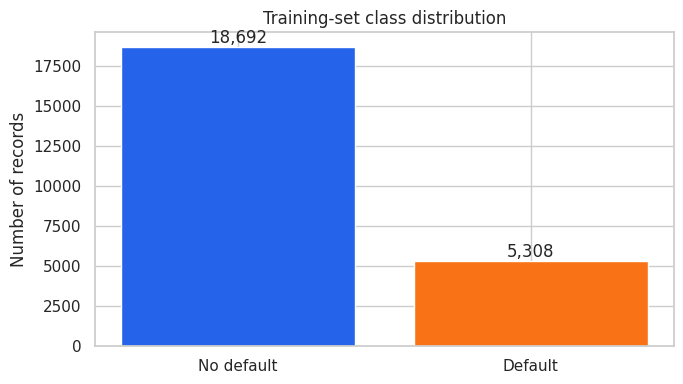

In [25]:
class_counts = y_train.value_counts().sort_index()
class_labels = ["No default", "Default"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_labels, class_counts.values, color=["#2563EB", "#F97316"])
ax.set_title("Training-set class distribution")
ax.set_ylabel("Number of records")
ax.bar_label(bars, labels=[f"{count:,}" for count in class_counts.values])
plt.tight_layout()
plt.show()

In [26]:
DEMOGRAPHIC_FEATURES = ["sex", "education", "marriage", "age"]
BILL_FEATURES = [column for column in X if column.startswith("bill_statement_")]
PAYMENT_FEATURES = [column for column in X if column.startswith("previous_payment_")]
MONETARY_FEATURES = ["credit_limit", *BILL_FEATURES, *PAYMENT_FEATURES]
BEHAVIORAL_FEATURES = [*MONETARY_FEATURES, *REPAYMENT_FEATURES]

assert len(BEHAVIORAL_FEATURES) == 19
assert not set(BEHAVIORAL_FEATURES) & set(DEMOGRAPHIC_FEATURES)

monetary_summary = X_train[MONETARY_FEATURES].quantile(
    [0.00, 0.50, 0.95, 0.99, 1.00]
).T
monetary_summary.columns = ["minimum", "median", "p95", "p99", "maximum"]
monetary_summary["skew"] = X_train[MONETARY_FEATURES].skew()
display(monetary_summary.sort_values("skew", ascending=False))

,minimum,median,p95,p99,maximum,skew
previous_payment_aug,0.0,2011.0,18987.50,76656.47,1684259.0,31.123810
previous_payment_jul,0.0,1800.0,17297.50,70092.83,896040.0,18.548818
previous_payment_sep,0.0,2105.0,18417.55,65593.30,873552.0,15.750503
previous_payment_jun,0.0,1500.0,16000.00,65349.79,621000.0,12.261438
previous_payment_may,0.0,1500.0,15830.70,65607.56,417990.0,10.863745
previous_payment_apr,0.0,1500.0,17558.70,83577.27,528666.0,10.709372
bill_statement_jul,-157264.0,20015.0,186878.35,322077.82,1664089.0,3.178145
bill_statement_may,-81334.0,18066.0,165077.10,284627.09,927171.0,2.899662
bill_statement_apr,-339603.0,16928.0,161212.55,276227.70,961664.0,2.859245
bill_statement_jun,-65167.0,19005.5,173469.40,301905.10,891586.0,2.818024


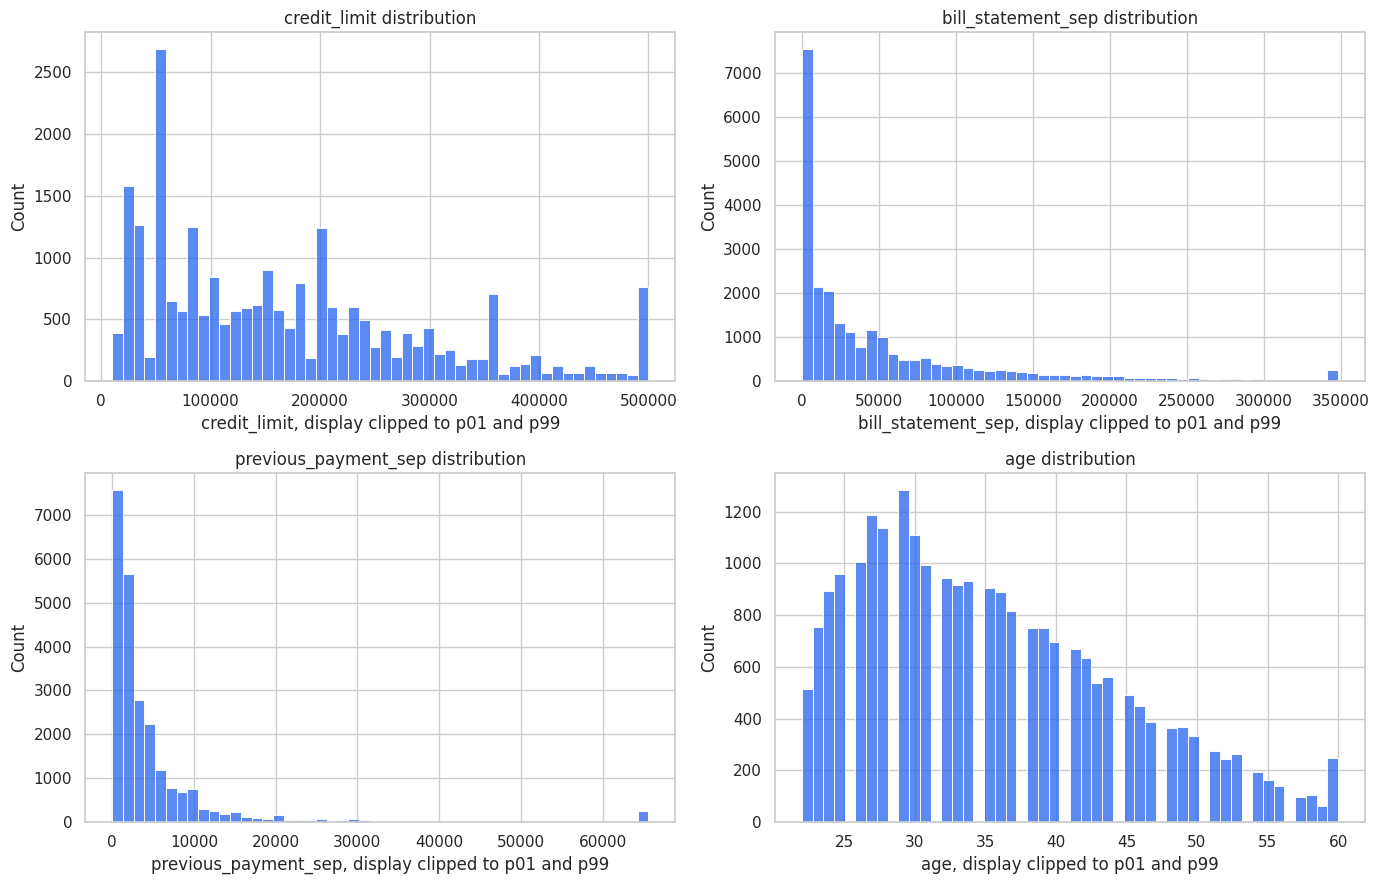

In [27]:
plot_features = ["credit_limit", "bill_statement_sep", "previous_payment_sep", "age"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flat, plot_features):
    lower = X_train[column].quantile(0.01)
    upper = X_train[column].quantile(0.99)
    display_values = X_train[column].clip(lower=lower, upper=upper)
    sns.histplot(display_values, bins=50, ax=ax, color="#2563EB")
    ax.set_title(f"{column} distribution")
    ax.set_xlabel(f"{column}, display clipped to p01 and p99")

plt.tight_layout()
plt.show()

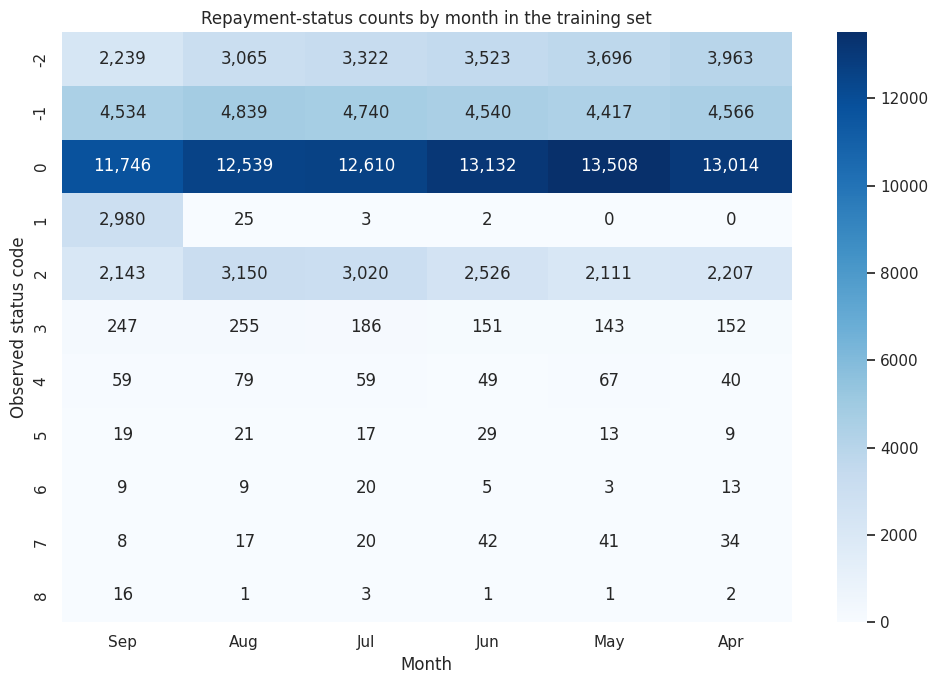

In [28]:
repayment_counts = (
    X_train[REPAYMENT_FEATURES]
    .melt(var_name="month", value_name="status")
    .groupby(["status", "month"])
    .size()
    .unstack(fill_value=0)
)
repayment_counts = repayment_counts.loc[:, REPAYMENT_FEATURES]
repayment_counts.columns = [column.rsplit("_", 1)[-1].title() for column in repayment_counts]

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(repayment_counts, cmap="Blues", annot=True, fmt=",d", ax=ax)
ax.set_title("Repayment-status counts by month in the training set")
ax.set_xlabel("Month")
ax.set_ylabel("Observed status code")
plt.tight_layout()
plt.show()

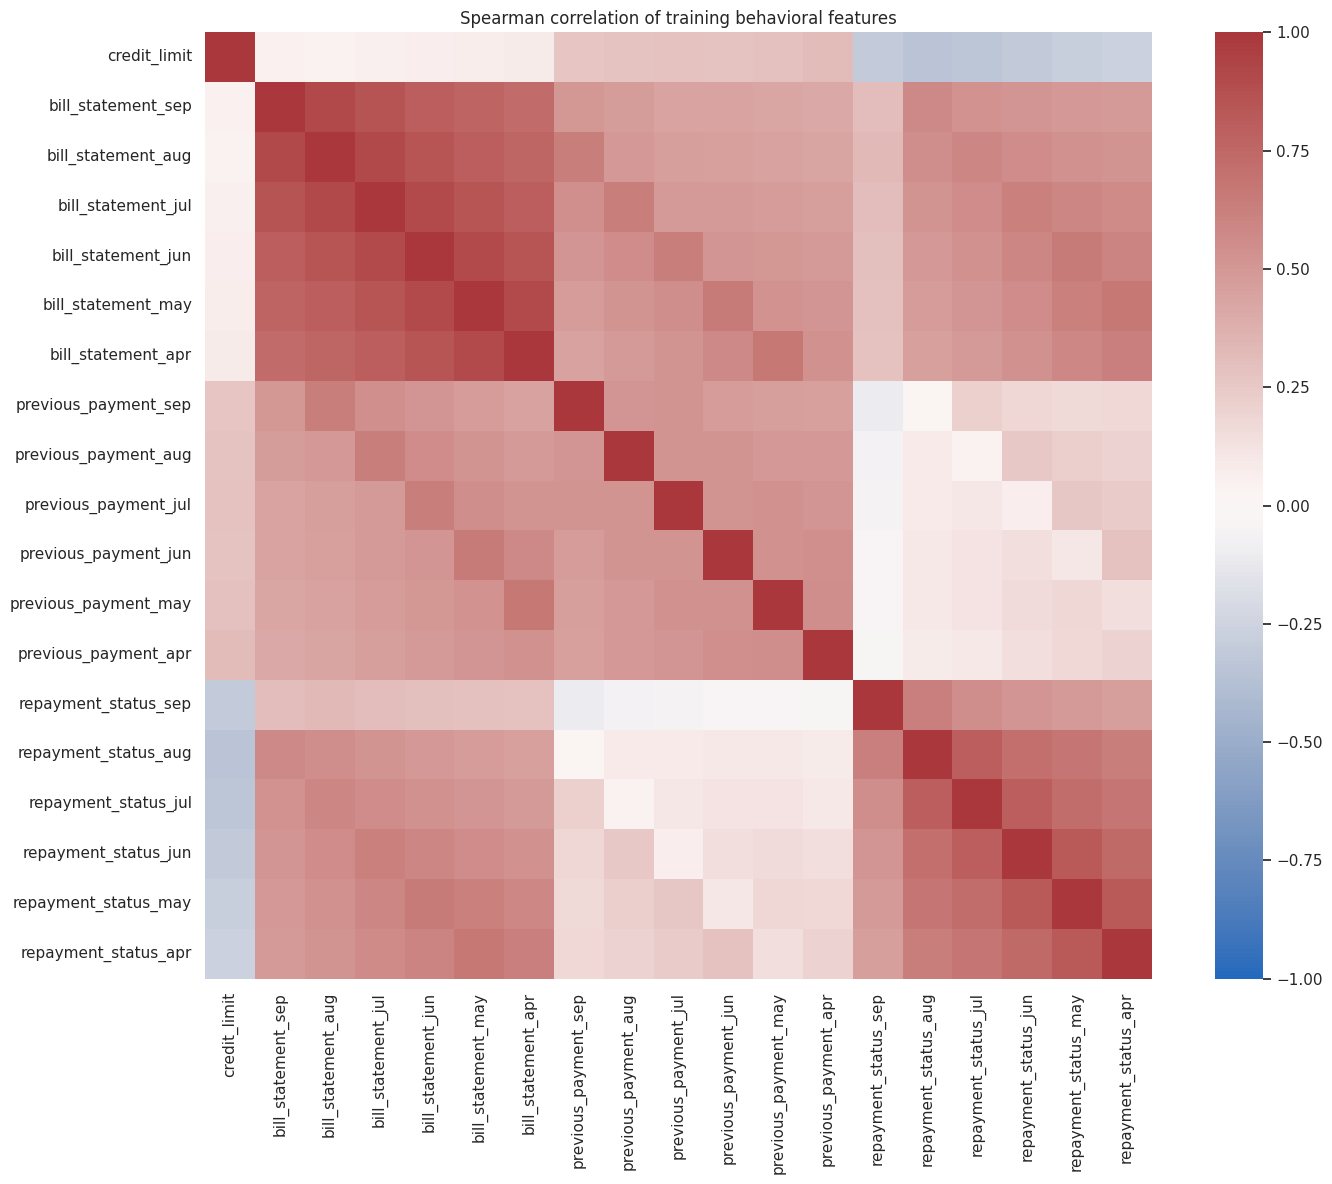

In [29]:
correlation = X_train[BEHAVIORAL_FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    correlation,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Spearman correlation of training behavioral features")
plt.tight_layout()
plt.show()

,default_rate,count
repayment_status_sep,,
-2,13.18%,2239
-1,16.50%,4534
0,12.83%,11746
1,34.23%,2980
2,69.02%,2143
3,76.52%,247
4,66.10%,59
5,52.63%,19
6,66.67%,9


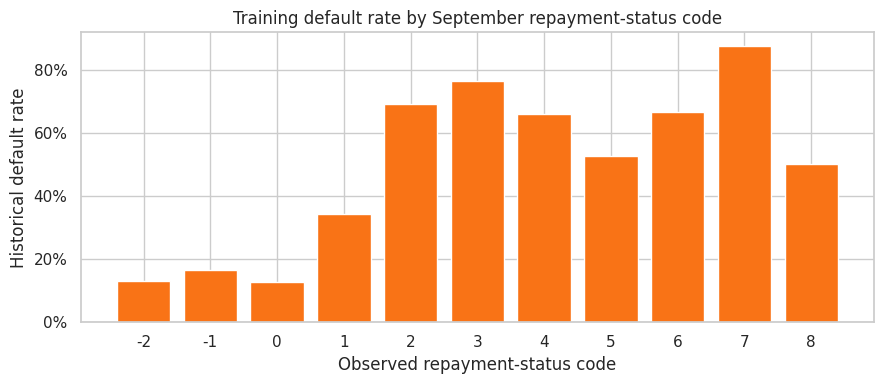

In [30]:
training_analysis = X_train.assign(default_next_month=y_train)
default_by_status = (
    training_analysis.groupby("repayment_status_sep")["default_next_month"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "default_rate"})
)
display(default_by_status.style.format({"default_rate": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(default_by_status.index.astype(str), default_by_status["default_rate"], color="#F97316")
ax.set_title("Training default rate by September repayment-status code")
ax.set_xlabel("Observed repayment-status code")
ax.set_ylabel("Historical default rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 6. Compare leakage-safe preprocessing strategies

Three candidates are fitted on the behavioral training features only:

- Standard scaling for all features.
- Robust scaling for all features.
- Yeo-Johnson for monetary features and standard scaling for repayment-status features.

Yeo-Johnson supports negative and zero values. The mixed strategy avoids applying a power transform to ordinal repayment codes.

In [31]:
X_train_behavioral = X_train.loc[:, BEHAVIORAL_FEATURES]
PREPROCESSOR_CANDIDATES = {
    "standard_scaler": StandardScaler(),
    "robust_scaler": RobustScaler(quantile_range=(25.0, 75.0)),
    "mixed_power_standard": ColumnTransformer(
        transformers=[
            (
                "monetary",
                PowerTransformer(method="yeo-johnson", standardize=True),
                MONETARY_FEATURES,
            ),
            ("repayment", StandardScaler(), REPAYMENT_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ),
}

comparison_rows = []
variance_curves = {}
fitted_candidates = {}
transformed_training_data = {}

for name, candidate in PREPROCESSOR_CANDIDATES.items():
    fitted = clone(candidate)
    transformed = np.asarray(fitted.fit_transform(X_train_behavioral), dtype=float)
    assert transformed.shape == (len(X_train_behavioral), len(BEHAVIORAL_FEATURES))
    assert np.isfinite(transformed).all()

    full_pca = PCA(svd_solver="full").fit(transformed)
    cumulative_variance = np.cumsum(full_pca.explained_variance_ratio_)
    pca_95_candidate = PCA(n_components=0.95, svd_solver="full").fit(transformed)
    reconstructed = pca_95_candidate.inverse_transform(
        pca_95_candidate.transform(transformed)
    )
    transformed_skew = pd.DataFrame(transformed).skew().abs()

    variance_curves[name] = cumulative_variance
    fitted_candidates[name] = fitted
    transformed_training_data[name] = transformed
    comparison_rows.append(
        {
            "preprocessor": name,
            "mean absolute skew": float(transformed_skew.mean()),
            "maximum absolute skew": float(transformed_skew.max()),
            "components for 80%": int(np.searchsorted(cumulative_variance, 0.80) + 1),
            "components for 90%": int(np.searchsorted(cumulative_variance, 0.90) + 1),
            "components for 95%": int(np.searchsorted(cumulative_variance, 0.95) + 1),
            "first two component variance": float(cumulative_variance[1]),
            "95% reconstruction MSE": float(
                np.mean((transformed - reconstructed) ** 2)
            ),
        }
    )

preprocessing_comparison = pd.DataFrame(comparison_rows).set_index("preprocessor")
display(preprocessing_comparison)

,mean absolute skew,maximum absolute skew,components for 80%,components for 90%,components for 95%,first two component variance,95% reconstruction MSE
preprocessor,,,,,,,
standard_scaler,6.452937,31.123810,7,10,12,0.557320,0.038357
robust_scaler,6.452937,31.123810,6,7,8,0.466548,0.167612
mixed_power_standard,0.976883,3.571222,7,10,13,0.592945,0.043713


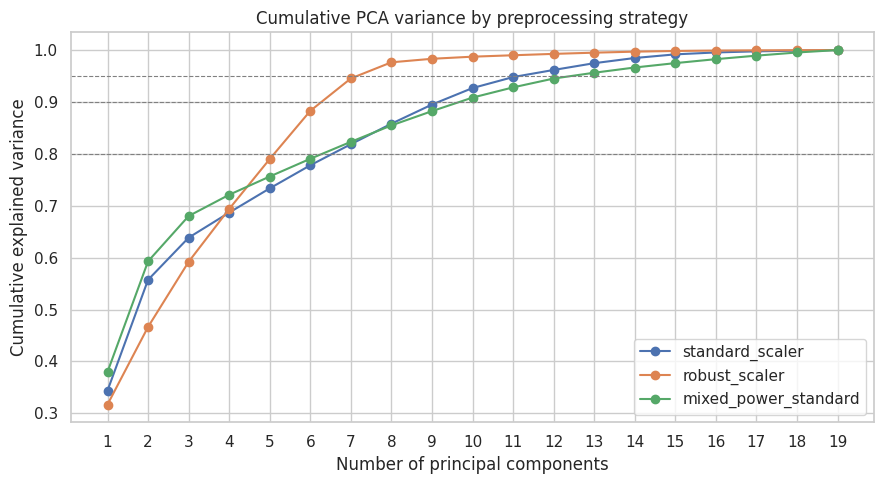

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, cumulative_variance in variance_curves.items():
    component_numbers = np.arange(1, len(cumulative_variance) + 1)
    ax.plot(component_numbers, cumulative_variance, marker="o", label=name)

for threshold in [0.80, 0.90, 0.95]:
    ax.axhline(threshold, color="gray", linestyle="--", linewidth=0.8)

ax.set_title("Cumulative PCA variance by preprocessing strategy")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(np.arange(1, len(BEHAVIORAL_FEATURES) + 1))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Fit and interpret provisional PCA

The mixed strategy is the provisional choice because it addresses monetary skew while preserving the ordinal treatment of repayment-status codes. It may be revised if downstream validation favors another strategy.

In [33]:
SELECTED_PREPROCESSOR = "mixed_power_standard"
selected_preprocessor = fitted_candidates[SELECTED_PREPROCESSOR]
X_train_preprocessed = transformed_training_data[SELECTED_PREPROCESSOR]

pca_95 = PCA(n_components=0.95, svd_solver="full")
X_train_pca_95 = pca_95.fit_transform(X_train_preprocessed)

pca_2d = PCA(n_components=2, svd_solver="full")
X_train_pca_2d = pca_2d.fit_transform(X_train_preprocessed)

pca_summary = pd.Series(
    {
        "input features": X_train_preprocessed.shape[1],
        "components retained for at least 95% variance": pca_95.n_components_,
        "retained variance": pca_95.explained_variance_ratio_.sum(),
        "variance in first two components": pca_2d.explained_variance_ratio_.sum(),
    },
    name="value",
)
display(pca_summary.to_frame())

,value
input features,19.000000
components retained for at least 95% variance,13.000000
retained variance,0.956287
variance in first two components,0.592945


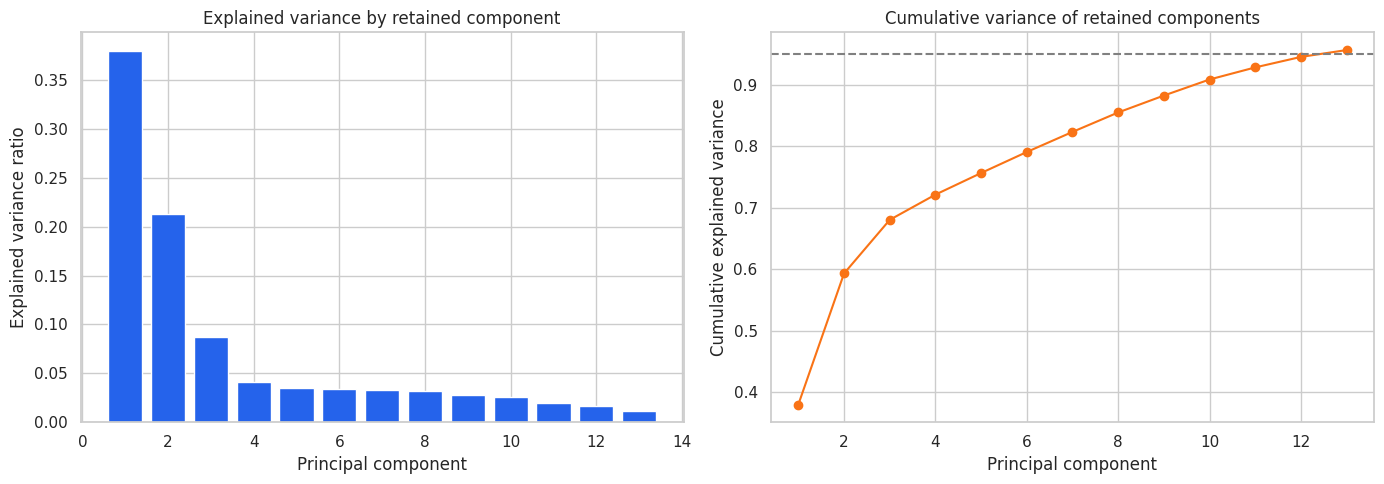

In [34]:
component_numbers = np.arange(1, pca_95.n_components_ + 1)
cumulative_variance = np.cumsum(pca_95.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(component_numbers, pca_95.explained_variance_ratio_, color="#2563EB")
axes[0].set_title("Explained variance by retained component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")

axes[1].plot(component_numbers, cumulative_variance, marker="o", color="#F97316")
axes[1].axhline(0.95, color="gray", linestyle="--")
axes[1].set_title("Cumulative variance of retained components")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative explained variance")

plt.tight_layout()
plt.show()

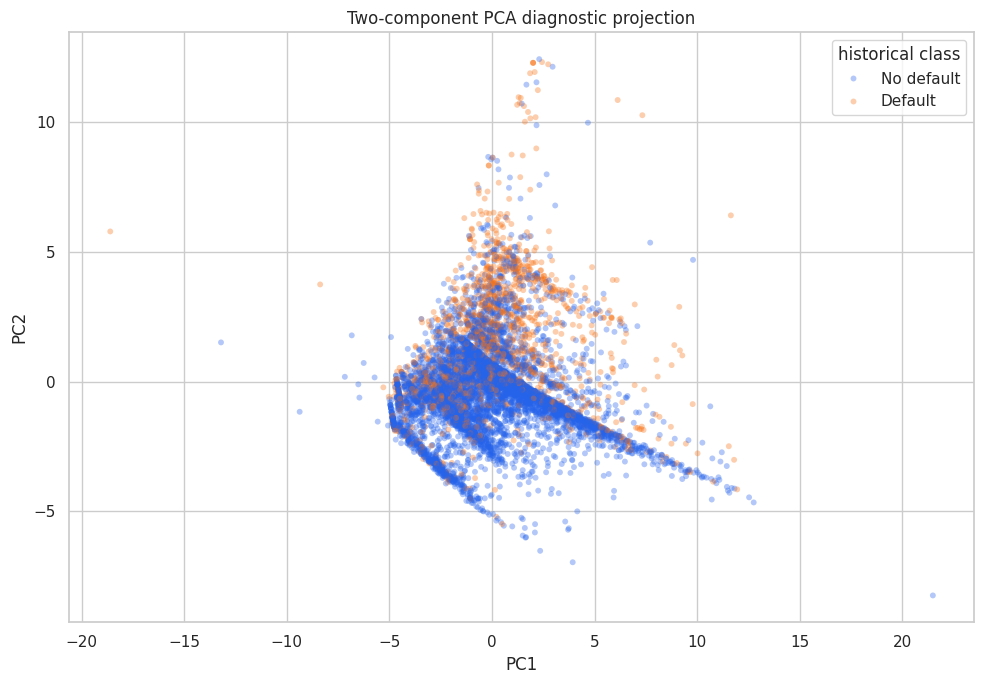

In [35]:
plot_rng = np.random.default_rng(RANDOM_STATE)
plot_size = min(8_000, len(X_train_pca_2d))
plot_indices = plot_rng.choice(len(X_train_pca_2d), size=plot_size, replace=False)
projection = pd.DataFrame(
    {
        "PC1": X_train_pca_2d[plot_indices, 0],
        "PC2": X_train_pca_2d[plot_indices, 1],
        "historical class": y_train.iloc[plot_indices].map(
            {0: "No default", 1: "Default"}
        ).to_numpy(),
    }
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=projection,
    x="PC1",
    y="PC2",
    hue="historical class",
    palette={"No default": "#2563EB", "Default": "#F97316"},
    alpha=0.35,
    s=18,
    linewidth=0,
    ax=ax,
)
ax.set_title("Two-component PCA diagnostic projection")
plt.tight_layout()
plt.show()

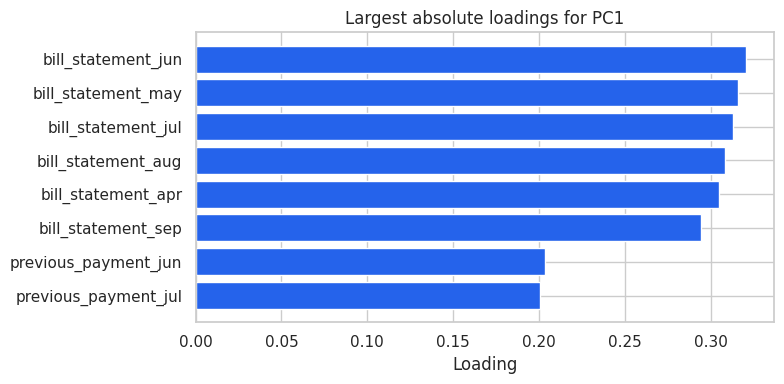

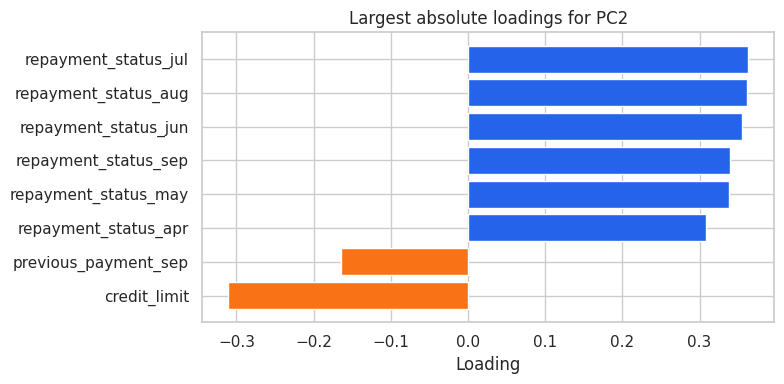

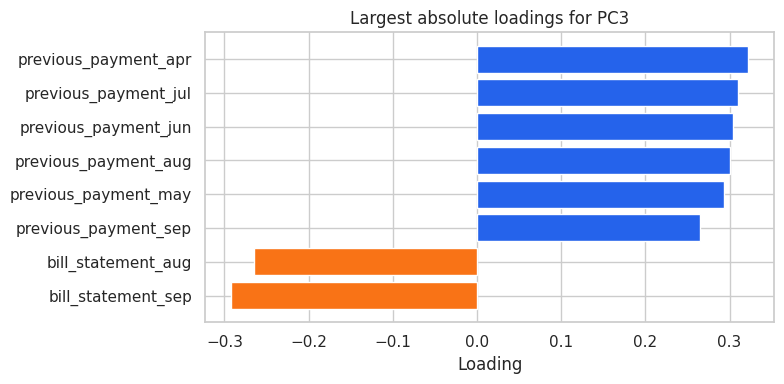

In [36]:
TRANSFORMED_FEATURE_ORDER = [*MONETARY_FEATURES, *REPAYMENT_FEATURES]
loading_count = min(3, pca_95.n_components_)
loadings = pd.DataFrame(
    pca_95.components_[:loading_count].T,
    index=TRANSFORMED_FEATURE_ORDER,
    columns=[f"PC{index}" for index in range(1, loading_count + 1)],
)

for component in loadings.columns:
    top_features = loadings[component].abs().nlargest(8).index
    component_loadings = loadings.loc[top_features, component].sort_values()
    colors = ["#F97316" if value < 0 else "#2563EB" for value in component_loadings]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(component_loadings.index, component_loadings.values, color=colors)
    ax.set_title(f"Largest absolute loadings for {component}")
    ax.set_xlabel("Loading")
    plt.tight_layout()
    plt.show()

## 8. Export provisional artifacts

These files are fitted on the training split only. They remain provisional until K-Means, DBSCAN, and supervised classification are complete. Kaggle places them in the notebook Output section.

In [37]:
joblib.dump(selected_preprocessor, output_directory / "behavioral_preprocessor.joblib")
joblib.dump(pca_95, output_directory / "behavioral_pca_95.joblib")
preprocessing_comparison.to_csv(output_directory / "preprocessing_comparison.csv")

artifact_metadata = {
    "dataset_id": UCI_DATASET_ID,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "training_rows": int(len(X_train)),
    "test_rows_held_out": int(len(X_test)),
    "selected_preprocessor": SELECTED_PREPROCESSOR,
    "input_features": BEHAVIORAL_FEATURES,
    "transformed_feature_order": TRANSFORMED_FEATURE_ORDER,
    "pca_components": int(pca_95.n_components_),
    "pca_retained_variance": float(pca_95.explained_variance_ratio_.sum()),
    "status": "provisional",
}
with (output_directory / "pca_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(artifact_metadata, file, indent=2)

created_artifacts = [
    "split_manifest.csv",
    "behavioral_preprocessor.joblib",
    "behavioral_pca_95.joblib",
    "preprocessing_comparison.csv",
    "pca_metadata.json",
]
print("Created artifacts:")
for artifact_name in created_artifacts:
    print(f"- {artifact_name}")

Created artifacts:
- split_manifest.csv
- behavioral_preprocessor.joblib
- behavioral_pca_95.joblib
- preprocessing_comparison.csv
- pca_metadata.json


## 9. K-Means representation setup

K-Means is compared on the full 19-feature preprocessed space and on PCA representations retaining at least 90% and 95% of training variance. The target remains excluded from fitting and model selection.

In [38]:
full_pca_for_clustering = PCA(svd_solver="full").fit(X_train_preprocessed)
full_cumulative_variance = np.cumsum(
    full_pca_for_clustering.explained_variance_ratio_
)
components_90 = int(np.searchsorted(full_cumulative_variance, 0.90) + 1)
components_95 = int(np.searchsorted(full_cumulative_variance, 0.95) + 1)

pca_90_for_clustering = PCA(
    n_components=components_90,
    svd_solver="full",
).fit(X_train_preprocessed)

CLUSTER_REPRESENTATIONS = {
    "preprocessed_19": X_train_preprocessed,
    f"pca_90_{components_90}": pca_90_for_clustering.transform(
        X_train_preprocessed
    ),
    f"pca_95_{components_95}": X_train_pca_95,
}
CLUSTER_REDUCERS = {
    "preprocessed_19": None,
    f"pca_90_{components_90}": pca_90_for_clustering,
    f"pca_95_{components_95}": pca_95,
}

representation_summary = pd.DataFrame(
    [
        {
            "representation": name,
            "rows": values.shape[0],
            "dimensions": values.shape[1],
        }
        for name, values in CLUSTER_REPRESENTATIONS.items()
    ]
).set_index("representation")
display(representation_summary)

,rows,dimensions
representation,,
preprocessed_19,24000,19
pca_90_10,24000,10
pca_95_13,24000,13


## 10. Evaluate cluster counts

Cluster counts from 2 through 8 are compared. Silhouette score uses a fixed 5,000-row sample to keep the pairwise-distance calculation practical. Other metrics use the full training set. Inertia is compared only within the same representation because its magnitude changes with dimensionality.

In [39]:
K_VALUES = range(2, 9)
SILHOUETTE_SAMPLE_SIZE = 5_000
kmeans_rows = []

for representation_name, representation_values in CLUSTER_REPRESENTATIONS.items():
    for cluster_count in K_VALUES:
        candidate_model = KMeans(
            n_clusters=cluster_count,
            init="k-means++",
            n_init=20,
            max_iter=500,
            random_state=RANDOM_STATE,
            algorithm="lloyd",
        )
        candidate_labels = candidate_model.fit_predict(representation_values)
        cluster_sizes = np.bincount(
            candidate_labels,
            minlength=cluster_count,
        )

        kmeans_rows.append(
            {
                "representation": representation_name,
                "clusters": cluster_count,
                "inertia": float(candidate_model.inertia_),
                "silhouette": float(
                    silhouette_score(
                        representation_values,
                        candidate_labels,
                        sample_size=SILHOUETTE_SAMPLE_SIZE,
                        random_state=RANDOM_STATE,
                    )
                ),
                "calinski_harabasz": float(
                    calinski_harabasz_score(
                        representation_values,
                        candidate_labels,
                    )
                ),
                "davies_bouldin": float(
                    davies_bouldin_score(
                        representation_values,
                        candidate_labels,
                    )
                ),
                "minimum_cluster_share": float(
                    cluster_sizes.min() / len(candidate_labels)
                ),
                "largest_to_smallest_ratio": float(
                    cluster_sizes.max() / cluster_sizes.min()
                ),
            }
        )

kmeans_evaluation = pd.DataFrame(kmeans_rows)
display(
    kmeans_evaluation.sort_values(
        ["silhouette", "davies_bouldin"],
        ascending=[False, True],
    ).head(12)
)

,representation,clusters,inertia,silhouette,calinski_harabasz,davies_bouldin,minimum_cluster_share,largest_to_smallest_ratio
7,pca_90_10,2,311539.818881,0.263753,7910.402610,1.336706,0.248625,3.022122
14,pca_95_13,2,333368.460445,0.253624,7392.944921,1.381863,0.248500,3.024145
0,preprocessed_19,2,353300.006552,0.247099,6975.942136,1.408650,0.248167,3.029550
8,pca_90_10,3,246604.937872,0.242451,8155.822836,1.419912,0.169708,2.930764
9,pca_90_10,4,213259.072026,0.241882,7537.825454,1.365021,0.142500,3.318129
10,pca_90_10,5,192204.006766,0.236945,6929.535273,1.411745,0.100625,3.919255
15,pca_95_13,3,268415.786332,0.230936,7494.216021,1.477587,0.171792,2.877759
16,pca_95_13,4,235004.214671,0.229049,6843.437541,1.423463,0.143250,3.287958
1,preprocessed_19,3,288346.105671,0.224514,6976.325720,1.513648,0.171667,2.880097
17,pca_95_13,5,213900.314781,0.223340,6230.586287,1.473619,0.100792,3.917321


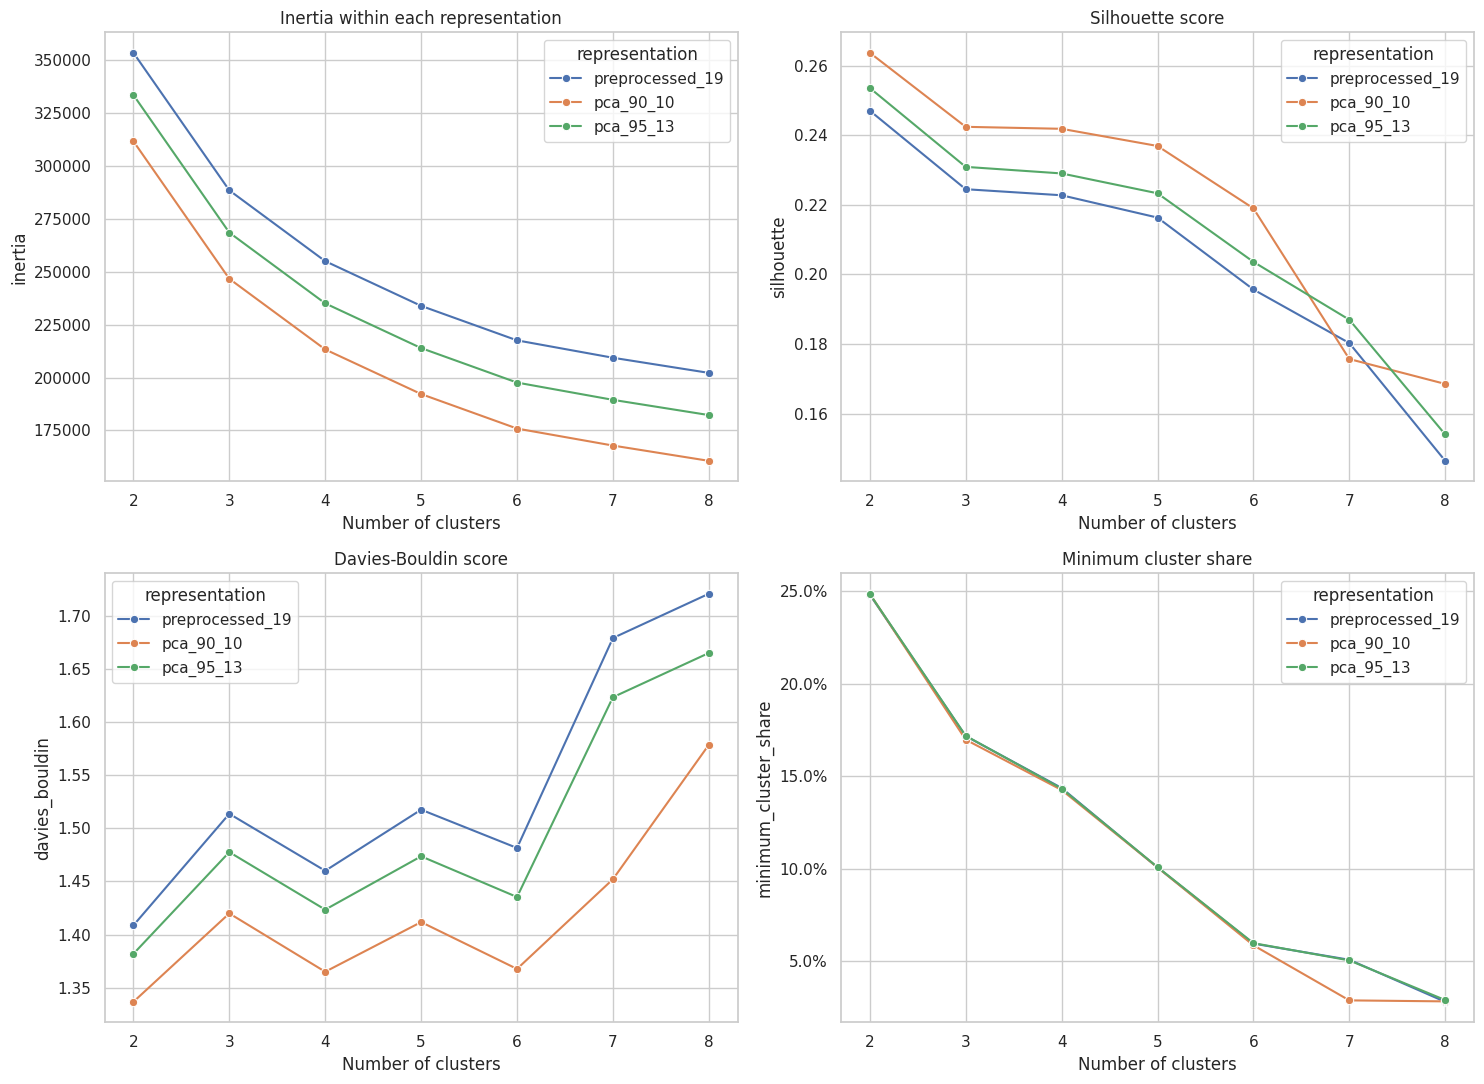

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
metric_specs = [
    ("inertia", "Inertia within each representation"),
    ("silhouette", "Silhouette score"),
    ("davies_bouldin", "Davies-Bouldin score"),
    ("minimum_cluster_share", "Minimum cluster share"),
]

for ax, (metric, title) in zip(axes.flat, metric_specs):
    sns.lineplot(
        data=kmeans_evaluation,
        x="clusters",
        y=metric,
        hue="representation",
        marker="o",
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Number of clusters")

axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 11. Select a provisional K-Means configuration

Configurations with a cluster smaller than 5% of the training data are excluded from automatic selection. The remaining candidates are ranked across silhouette, Calinski-Harabasz, Davies-Bouldin, and cluster-size balance. This creates a reproducible shortlist, but business usefulness is still checked through profiles before the choice becomes final.

In [41]:
eligible_kmeans = kmeans_evaluation.loc[
    kmeans_evaluation["minimum_cluster_share"] >= 0.05
].copy()
if eligible_kmeans.empty:
    eligible_kmeans = kmeans_evaluation.copy()

eligible_kmeans["silhouette_rank"] = eligible_kmeans["silhouette"].rank(
    ascending=False,
    method="min",
)
eligible_kmeans["calinski_rank"] = eligible_kmeans["calinski_harabasz"].rank(
    ascending=False,
    method="min",
)
eligible_kmeans["davies_rank"] = eligible_kmeans["davies_bouldin"].rank(
    ascending=True,
    method="min",
)
eligible_kmeans["balance_rank"] = eligible_kmeans["minimum_cluster_share"].rank(
    ascending=False,
    method="min",
)
eligible_kmeans["selection_rank_sum"] = eligible_kmeans[
    ["silhouette_rank", "calinski_rank", "davies_rank", "balance_rank"]
].sum(axis=1)

kmeans_shortlist = eligible_kmeans.sort_values(
    ["selection_rank_sum", "silhouette"],
    ascending=[True, False],
).head(5)
display(kmeans_shortlist)

selected_kmeans_row = kmeans_shortlist.iloc[0]
SELECTED_CLUSTER_REPRESENTATION = str(selected_kmeans_row["representation"])
SELECTED_CLUSTER_COUNT = int(selected_kmeans_row["clusters"])
selected_cluster_values = CLUSTER_REPRESENTATIONS[
    SELECTED_CLUSTER_REPRESENTATION
]
selected_cluster_reducer = CLUSTER_REDUCERS[SELECTED_CLUSTER_REPRESENTATION]

selected_kmeans = KMeans(
    n_clusters=SELECTED_CLUSTER_COUNT,
    init="k-means++",
    n_init=50,
    max_iter=500,
    random_state=RANDOM_STATE,
    algorithm="lloyd",
)
selected_cluster_labels = selected_kmeans.fit_predict(selected_cluster_values)

print(f"Selected representation: {SELECTED_CLUSTER_REPRESENTATION}")
print(f"Selected number of clusters: {SELECTED_CLUSTER_COUNT}")

,representation,clusters,inertia,silhouette,calinski_harabasz,davies_bouldin,minimum_cluster_share,largest_to_smallest_ratio,silhouette_rank,calinski_rank,davies_rank,balance_rank,selection_rank_sum
7,pca_90_10,2,311539.818881,0.263753,7910.402610,1.336706,0.248625,3.022122,1.0,2.0,1.0,1.0,5.0
14,pca_95_13,2,333368.460445,0.253624,7392.944921,1.381863,0.248500,3.024145,2.0,5.0,4.0,2.0,13.0
0,preprocessed_19,2,353300.006552,0.247099,6975.942136,1.408650,0.248167,3.029550,3.0,7.0,5.0,3.0,18.0
8,pca_90_10,3,246604.937872,0.242451,8155.822836,1.419912,0.169708,2.930764,4.0,1.0,7.0,6.0,18.0
9,pca_90_10,4,213259.072026,0.241882,7537.825454,1.365021,0.142500,3.318129,5.0,3.0,2.0,9.0,19.0


Selected representation: pca_90_10
Selected number of clusters: 2


## 12. Check initialization stability

Adjusted Rand Index compares each repeated fit with the selected labels while ignoring arbitrary cluster-number permutations. Values near 1 indicate stable assignments across initialization seeds.

In [42]:
STABILITY_SEEDS = [7, 21, 42, 84, 168]
stability_rows = []

for seed in STABILITY_SEEDS:
    repeated_model = KMeans(
        n_clusters=SELECTED_CLUSTER_COUNT,
        init="k-means++",
        n_init=20,
        max_iter=500,
        random_state=seed,
        algorithm="lloyd",
    )
    repeated_labels = repeated_model.fit_predict(selected_cluster_values)
    repeated_sizes = np.bincount(
        repeated_labels,
        minlength=SELECTED_CLUSTER_COUNT,
    )
    stability_rows.append(
        {
            "seed": seed,
            "adjusted_rand_index": adjusted_rand_score(
                selected_cluster_labels,
                repeated_labels,
            ),
            "minimum_cluster_share": repeated_sizes.min() / len(repeated_labels),
        }
    )

kmeans_stability = pd.DataFrame(stability_rows)
display(kmeans_stability)
print(
    "Mean adjusted Rand stability: "
    f"{kmeans_stability['adjusted_rand_index'].mean():.3f}"
)

,seed,adjusted_rand_index,minimum_cluster_share
0,7,0.999465,0.246708
1,21,0.999465,0.246458
2,42,0.991284,0.248625
3,84,0.997859,0.246167
4,168,0.991993,0.248458


Mean adjusted Rand stability: 0.996


## 13. Profile and visualize the clusters

Profiles use original training units for interpretation. Historical default rate is added only after clustering as a descriptive outcome. It did not influence cluster fitting or selection.

In [43]:
cluster_profile_data = X_train.loc[:, BEHAVIORAL_FEATURES].copy()
cluster_profile_data["average_bill"] = X_train[BILL_FEATURES].mean(axis=1)
cluster_profile_data["average_previous_payment"] = X_train[PAYMENT_FEATURES].mean(axis=1)
cluster_profile_data["average_repayment_status"] = X_train[REPAYMENT_FEATURES].mean(axis=1)
cluster_profile_data["average_bill_to_limit"] = (
    cluster_profile_data["average_bill"]
    / cluster_profile_data["credit_limit"]
)
cluster_profile_data["historical_default"] = y_train.to_numpy()
cluster_profile_data["cluster"] = selected_cluster_labels

PROFILE_FEATURES = [
    "credit_limit",
    "average_bill",
    "average_previous_payment",
    "average_repayment_status",
    "average_bill_to_limit",
]
cluster_profiles = cluster_profile_data.groupby("cluster")[PROFILE_FEATURES].median()
cluster_sizes = cluster_profile_data["cluster"].value_counts().sort_index()
cluster_default_rates = cluster_profile_data.groupby("cluster")[
    "historical_default"
].mean()
cluster_profiles.insert(0, "records", cluster_sizes)
cluster_profiles.insert(1, "share", cluster_sizes / len(cluster_profile_data))
cluster_profiles.insert(2, "historical_default_rate", cluster_default_rates)

display(
    cluster_profiles.style.format(
        {
            "share": "{:.2%}",
            "historical_default_rate": "{:.2%}",
            "credit_limit": "{:,.0f}",
            "average_bill": "{:,.0f}",
            "average_previous_payment": "{:,.0f}",
            "average_repayment_status": "{:.2f}",
            "average_bill_to_limit": "{:.2f}",
        }
    )
)

,records,share,historical_default_rate,credit_limit,average_bill,average_previous_payment,average_repayment_status,average_bill_to_limit
cluster,,,,,,,,
0,18082,75.34%,22.65%,"100,000","12,028","1,654",-0.17,0.11
1,5918,24.66%,20.50%,"200,000","108,146","5,707",0.00,0.68


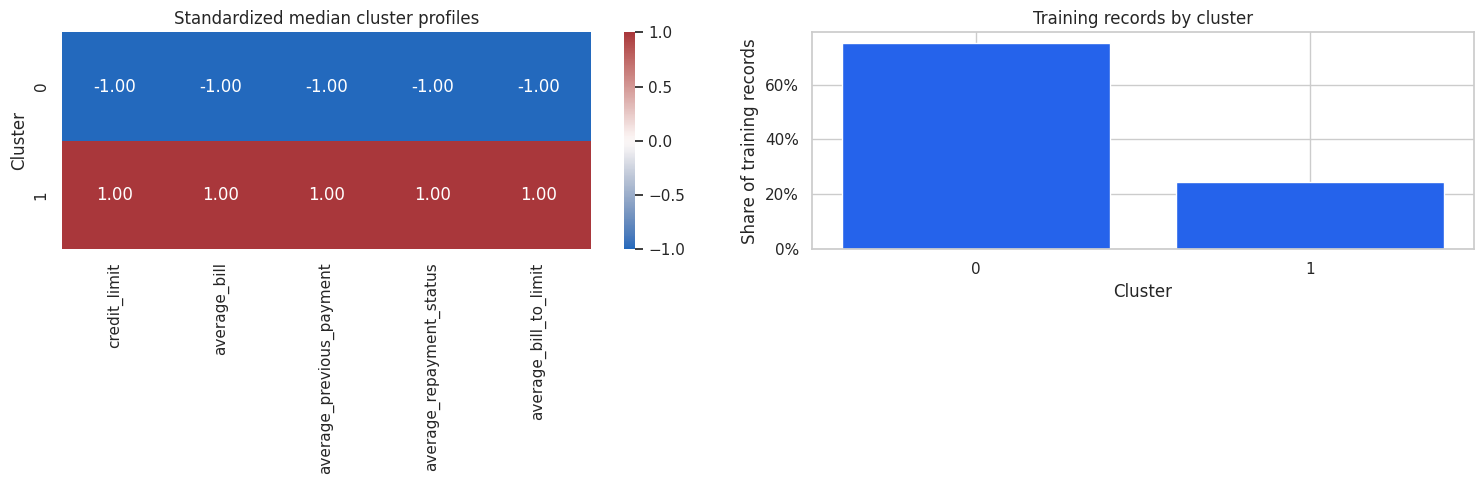

In [44]:
profile_values = cluster_profiles[PROFILE_FEATURES]
profile_scale = profile_values.std(axis=0, ddof=0).replace(0, 1)
standardized_profiles = (profile_values - profile_values.mean(axis=0)) / profile_scale

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(
    standardized_profiles,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[0],
)
axes[0].set_title("Standardized median cluster profiles")
axes[0].set_ylabel("Cluster")

axes[1].bar(
    cluster_profiles.index.astype(str),
    cluster_profiles["share"],
    color="#2563EB",
)
axes[1].set_title("Training records by cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Share of training records")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

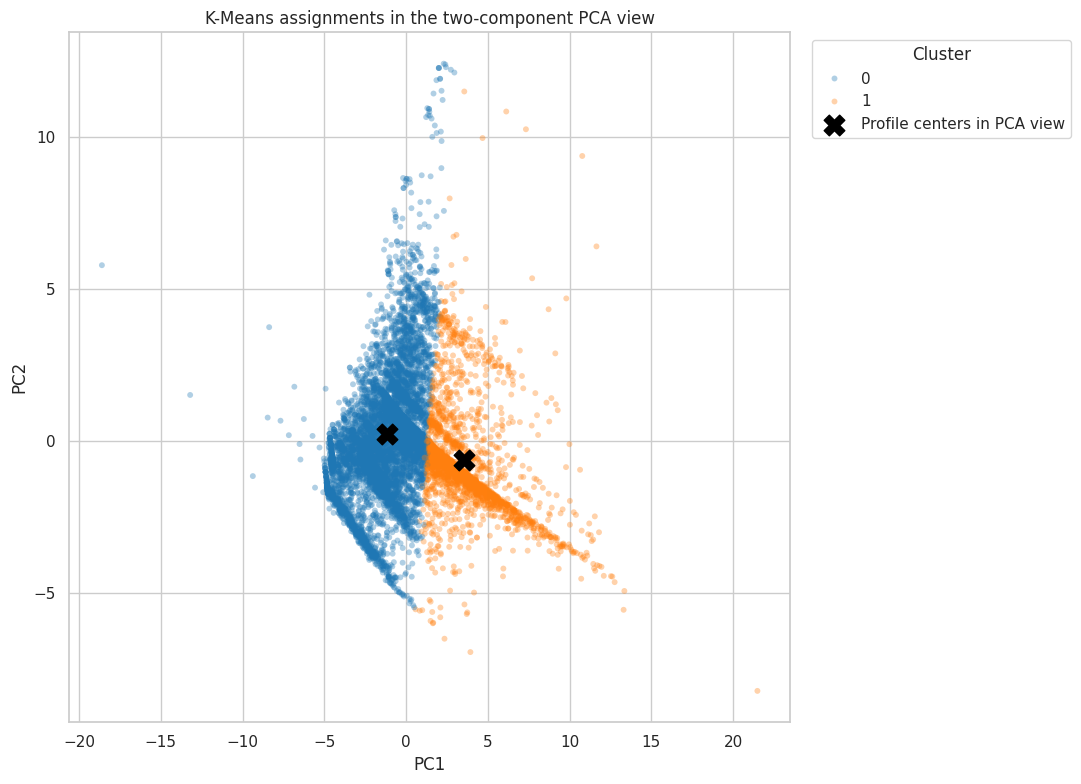

In [45]:
cluster_projection = pd.DataFrame(
    {
        "PC1": X_train_pca_2d[:, 0],
        "PC2": X_train_pca_2d[:, 1],
        "cluster": selected_cluster_labels.astype(str),
    }
)
plot_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(cluster_projection),
    size=min(10_000, len(cluster_projection)),
    replace=False,
)
plot_projection = cluster_projection.iloc[plot_indices]
centroid_projection = cluster_projection.assign(
    cluster_number=selected_cluster_labels
).groupby("cluster_number")[["PC1", "PC2"]].mean()

fig, ax = plt.subplots(figsize=(11, 8))
sns.scatterplot(
    data=plot_projection,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.35,
    s=18,
    linewidth=0,
    ax=ax,
)
ax.scatter(
    centroid_projection["PC1"],
    centroid_projection["PC2"],
    marker="X",
    s=220,
    c="black",
    label="Profile centers in PCA view",
)
ax.set_title("K-Means assignments in the two-component PCA view")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 14. Export provisional K-Means artifacts

The bundle contains the fitted behavioral preprocessor, the selected PCA reducer when applicable, the K-Means model, and the required feature order. Cluster numbers remain technical labels until the profiles are reviewed and given evidence-based names.

In [46]:
kmeans_bundle = {
    "preprocessor": selected_preprocessor,
    "pca": selected_cluster_reducer,
    "model": selected_kmeans,
    "input_features": BEHAVIORAL_FEATURES,
    "representation": SELECTED_CLUSTER_REPRESENTATION,
}
joblib.dump(kmeans_bundle, output_directory / "kmeans_bundle.joblib")
kmeans_evaluation.to_csv(output_directory / "kmeans_evaluation.csv", index=False)
kmeans_stability.to_csv(output_directory / "kmeans_stability.csv", index=False)
cluster_profiles.to_csv(output_directory / "kmeans_cluster_profiles.csv")

kmeans_metadata = {
    "representation": SELECTED_CLUSTER_REPRESENTATION,
    "clusters": SELECTED_CLUSTER_COUNT,
    "training_rows": int(len(selected_cluster_labels)),
    "silhouette_sample_size": SILHOUETTE_SAMPLE_SIZE,
    "selection_metrics": {
        "silhouette": float(selected_kmeans_row["silhouette"]),
        "calinski_harabasz": float(
            selected_kmeans_row["calinski_harabasz"]
        ),
        "davies_bouldin": float(selected_kmeans_row["davies_bouldin"]),
        "minimum_cluster_share": float(
            selected_kmeans_row["minimum_cluster_share"]
        ),
    },
    "mean_initialization_stability_ari": float(
        kmeans_stability["adjusted_rand_index"].mean()
    ),
    "status": "provisional",
}
with (output_directory / "kmeans_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(kmeans_metadata, file, indent=2)

print("K-Means artifacts created in the Kaggle Output directory.")

K-Means artifacts created in the Kaggle Output directory.


## 15. K-Means conclusions

Current decisions:

- The identifier is excluded from all models.
- The target is excluded from PCA and clustering inputs.
- The initial behavioral model excludes demographic features.
- Negative bill balances and extreme monetary observations are preserved.
- The mixed preprocessing pipeline remains provisional.
- K-Means selection uses several internal metrics, stability, size balance, and profile review.
- Cluster numbers are not given business names until their profiles support those names.
- The final supervised test split remains untouched.

The next section evaluates DBSCAN in reduced PCA spaces, measures noise rates and sensitivity, and compares its density-based structure with K-Means.

## 16. DBSCAN search setup

DBSCAN is evaluated as both a density-clustering method and an unusual-density detector. The search uses a fixed random sample of 8,000 training records to keep memory use predictable because DBSCAN can require quadratic memory in unfavorable cases.

Whitened PCA spaces with 2, 5, and 10 components are compared. Whitening prevents the first principal component from dominating Euclidean neighborhoods. The target is not used during sampling, fitting, or parameter selection.

In [47]:
DBSCAN_SAMPLE_SIZE = min(8_000, len(X_train_preprocessed))
dbscan_rng = np.random.default_rng(RANDOM_STATE)
dbscan_sample_indices = np.sort(
    dbscan_rng.choice(
        len(X_train_preprocessed),
        size=DBSCAN_SAMPLE_SIZE,
        replace=False,
    )
)

DBSCAN_DIMENSIONS = sorted(set([2, 5, components_90]))
DBSCAN_REPRESENTATIONS = {}
DBSCAN_REDUCERS = {}

for dimension_count in DBSCAN_DIMENSIONS:
    representation_name = f"pca_whitened_{dimension_count}"
    reducer = PCA(
        n_components=dimension_count,
        whiten=True,
        svd_solver="full",
    ).fit(X_train_preprocessed)
    DBSCAN_REDUCERS[representation_name] = reducer
    DBSCAN_REPRESENTATIONS[representation_name] = reducer.transform(
        X_train_preprocessed
    )[dbscan_sample_indices]

dbscan_representation_summary = pd.DataFrame(
    [
        {
            "representation": name,
            "sample rows": values.shape[0],
            "dimensions": values.shape[1],
        }
        for name, values in DBSCAN_REPRESENTATIONS.items()
    ]
).set_index("representation")
display(dbscan_representation_summary)

,sample rows,dimensions
representation,,
pca_whitened_2,8000,2
pca_whitened_5,8000,5
pca_whitened_10,8000,10


## 17. Derive and evaluate DBSCAN parameters

For every PCA space and min_samples value, candidate eps values are derived from the 90th, 95th, and 98th percentiles of the corresponding nearest-neighbor distance. This ties the search to observed density rather than arbitrary constants.

In [48]:
DBSCAN_MIN_SAMPLES = [10, 20, 40]
DBSCAN_EPS_QUANTILES = [0.90, 0.95, 0.98]
DBSCAN_SILHOUETTE_SAMPLE_SIZE = 3_000
dbscan_rows = []
dbscan_distance_curves = {}

for representation_name, representation_values in DBSCAN_REPRESENTATIONS.items():
    dimension_count = representation_values.shape[1]
    for min_samples in DBSCAN_MIN_SAMPLES:
        neighbor_model = NearestNeighbors(
            n_neighbors=min_samples,
            n_jobs=-1,
        ).fit(representation_values)
        neighbor_distances, _ = neighbor_model.kneighbors(representation_values)
        kth_neighbor_distances = neighbor_distances[:, -1]
        dbscan_distance_curves[(representation_name, min_samples)] = np.sort(
            kth_neighbor_distances
        )

        for eps_quantile in DBSCAN_EPS_QUANTILES:
            epsilon = float(np.quantile(kth_neighbor_distances, eps_quantile))
            candidate_model = DBSCAN(
                eps=epsilon,
                min_samples=min_samples,
                metric="euclidean",
                n_jobs=-1,
            )
            candidate_labels = candidate_model.fit_predict(representation_values)
            non_noise_mask = candidate_labels != -1
            core_labels = candidate_labels[non_noise_mask]
            cluster_count = len(set(int(label) for label in core_labels))
            noise_share = float((~non_noise_mask).mean())

            if core_labels.size:
                core_cluster_sizes = pd.Series(core_labels).value_counts()
                minimum_cluster_share = float(
                    core_cluster_sizes.min() / len(candidate_labels)
                )
                maximum_cluster_share = float(
                    core_cluster_sizes.max() / len(candidate_labels)
                )
            else:
                minimum_cluster_share = 0.0
                maximum_cluster_share = 0.0

            silhouette = np.nan
            calinski_harabasz = np.nan
            davies_bouldin = np.nan
            if cluster_count >= 2 and core_labels.size > cluster_count:
                core_values = representation_values[non_noise_mask]
                silhouette = float(
                    silhouette_score(
                        core_values,
                        core_labels,
                        sample_size=min(
                            DBSCAN_SILHOUETTE_SAMPLE_SIZE,
                            len(core_values),
                        ),
                        random_state=RANDOM_STATE,
                    )
                )
                calinski_harabasz = float(
                    calinski_harabasz_score(core_values, core_labels)
                )
                davies_bouldin = float(
                    davies_bouldin_score(core_values, core_labels)
                )

            dbscan_rows.append(
                {
                    "representation": representation_name,
                    "dimensions": dimension_count,
                    "min_samples": min_samples,
                    "eps_quantile": eps_quantile,
                    "eps": epsilon,
                    "clusters": cluster_count,
                    "noise_share": noise_share,
                    "minimum_cluster_share": minimum_cluster_share,
                    "maximum_cluster_share": maximum_cluster_share,
                    "silhouette_non_noise": silhouette,
                    "calinski_harabasz_non_noise": calinski_harabasz,
                    "davies_bouldin_non_noise": davies_bouldin,
                }
            )

dbscan_evaluation = pd.DataFrame(dbscan_rows)
display(dbscan_evaluation)

,representation,dimensions,min_samples,eps_quantile,eps,clusters,noise_share,minimum_cluster_share,maximum_cluster_share,silhouette_non_noise,calinski_harabasz_non_noise,davies_bouldin_non_noise
0,pca_whitened_2,2,10,0.90,0.130389,6,0.068250,0.001125,0.923625,-0.281553,44.312181,0.771195
1,pca_whitened_2,2,10,0.95,0.189666,3,0.030250,0.000750,0.967000,0.186103,50.340513,0.569905
2,pca_whitened_2,2,10,0.98,0.307167,4,0.009625,0.001250,0.986500,0.582078,156.720864,0.388252
3,pca_whitened_2,2,20,0.90,0.188579,1,0.063750,0.936250,0.936250,NaN,NaN,NaN
4,pca_whitened_2,2,20,0.95,0.275437,2,0.026500,0.002000,0.971500,0.342944,56.219827,0.523805
5,pca_whitened_2,2,20,0.98,0.437966,1,0.010750,0.989250,0.989250,NaN,NaN,NaN
6,pca_whitened_2,2,40,0.90,0.269112,1,0.055500,0.944500,0.944500,NaN,NaN,NaN
7,pca_whitened_2,2,40,0.95,0.387175,1,0.024375,0.975625,0.975625,NaN,NaN,NaN
8,pca_whitened_2,2,40,0.98,0.600461,1,0.009375,0.990625,0.990625,NaN,NaN,NaN
9,pca_whitened_5,5,10,0.90,0.924298,1,0.048500,0.951500,0.951500,NaN,NaN,NaN


## 18. Select clustering or anomaly-exploration mode

A multi-cluster DBSCAN solution is considered meaningful only when it has at least two clusters, noise between 1% and 30%, and every non-noise cluster contains at least 2% of the search sample. If no configuration satisfies those safeguards, the notebook switches to anomaly-exploration mode and chooses one dominant core cluster plus a moderate noise set. This prevents tiny fragments from being presented as customer segments.

In [49]:
meaningful_density_clusters = dbscan_evaluation.loc[
    (dbscan_evaluation["clusters"] >= 2)
    & (dbscan_evaluation["noise_share"].between(0.01, 0.30))
    & (dbscan_evaluation["minimum_cluster_share"] >= 0.02)
].copy()

if not meaningful_density_clusters.empty:
    DBSCAN_MODE = "density_clustering"
    meaningful_density_clusters["silhouette_rank"] = meaningful_density_clusters[
        "silhouette_non_noise"
    ].rank(ascending=False, method="min")
    meaningful_density_clusters["davies_rank"] = meaningful_density_clusters[
        "davies_bouldin_non_noise"
    ].rank(ascending=True, method="min")
    meaningful_density_clusters["balance_rank"] = meaningful_density_clusters[
        "minimum_cluster_share"
    ].rank(ascending=False, method="min")
    meaningful_density_clusters["selection_rank_sum"] = meaningful_density_clusters[
        ["silhouette_rank", "davies_rank", "balance_rank"]
    ].sum(axis=1)
    dbscan_shortlist = meaningful_density_clusters.sort_values(
        ["selection_rank_sum", "silhouette_non_noise"],
        ascending=[True, False],
    ).head(5)
else:
    DBSCAN_MODE = "anomaly_exploration"
    anomaly_candidates = dbscan_evaluation.loc[
        (dbscan_evaluation["clusters"] == 1)
        & (dbscan_evaluation["noise_share"].between(0.01, 0.10))
    ].copy()
    if anomaly_candidates.empty:
        anomaly_candidates = dbscan_evaluation.copy()

    anomaly_candidates["dimension_penalty"] = (
        anomaly_candidates["dimensions"] - 5
    ).abs()
    anomaly_candidates["quantile_penalty"] = (
        anomaly_candidates["eps_quantile"] - 0.95
    ).abs()
    anomaly_candidates["min_samples_penalty"] = (
        anomaly_candidates["min_samples"]
        - np.maximum(10, 2 * anomaly_candidates["dimensions"])
    ).abs()
    dbscan_shortlist = anomaly_candidates.sort_values(
        ["dimension_penalty", "quantile_penalty", "min_samples_penalty"],
        ascending=True,
    ).head(5)

display(dbscan_shortlist)
selected_dbscan_row = dbscan_shortlist.iloc[0]
SELECTED_DBSCAN_REPRESENTATION = str(selected_dbscan_row["representation"])
SELECTED_DBSCAN_EPS = float(selected_dbscan_row["eps"])
SELECTED_DBSCAN_MIN_SAMPLES = int(selected_dbscan_row["min_samples"])
selected_dbscan_values = DBSCAN_REPRESENTATIONS[
    SELECTED_DBSCAN_REPRESENTATION
]
selected_dbscan_reducer = DBSCAN_REDUCERS[SELECTED_DBSCAN_REPRESENTATION]

selected_dbscan = DBSCAN(
    eps=SELECTED_DBSCAN_EPS,
    min_samples=SELECTED_DBSCAN_MIN_SAMPLES,
    metric="euclidean",
    n_jobs=-1,
)
selected_dbscan_labels = selected_dbscan.fit_predict(selected_dbscan_values)
selected_dbscan_cluster_count = len(
    set(int(label) for label in selected_dbscan_labels if label != -1)
)
selected_dbscan_noise_share = float((selected_dbscan_labels == -1).mean())

print(f"DBSCAN mode: {DBSCAN_MODE}")
print(f"Selected representation: {SELECTED_DBSCAN_REPRESENTATION}")
print(f"Selected eps: {SELECTED_DBSCAN_EPS:.4f}")
print(f"Selected min_samples: {SELECTED_DBSCAN_MIN_SAMPLES}")
print(f"Non-noise clusters: {selected_dbscan_cluster_count}")
print(f"Noise share: {selected_dbscan_noise_share:.2%}")

,representation,dimensions,min_samples,eps_quantile,eps,clusters,noise_share,minimum_cluster_share,maximum_cluster_share,silhouette_non_noise,calinski_harabasz_non_noise,davies_bouldin_non_noise,dimension_penalty,quantile_penalty,min_samples_penalty
10,pca_whitened_5,5,10,0.95,1.152576,1,0.020750,0.979250,0.979250,NaN,NaN,NaN,0,0.00,0
13,pca_whitened_5,5,20,0.95,1.363272,1,0.016375,0.983625,0.983625,NaN,NaN,NaN,0,0.00,10
16,pca_whitened_5,5,40,0.95,1.591926,1,0.013125,0.986875,0.986875,NaN,NaN,NaN,0,0.00,30
9,pca_whitened_5,5,10,0.90,0.924298,1,0.048500,0.951500,0.951500,NaN,NaN,NaN,0,0.05,0
12,pca_whitened_5,5,20,0.90,1.100255,1,0.038625,0.961375,0.961375,NaN,NaN,NaN,0,0.05,10


DBSCAN mode: anomaly_exploration
Selected representation: pca_whitened_5
Selected eps: 1.1526
Selected min_samples: 10
Non-noise clusters: 1
Noise share: 2.08%


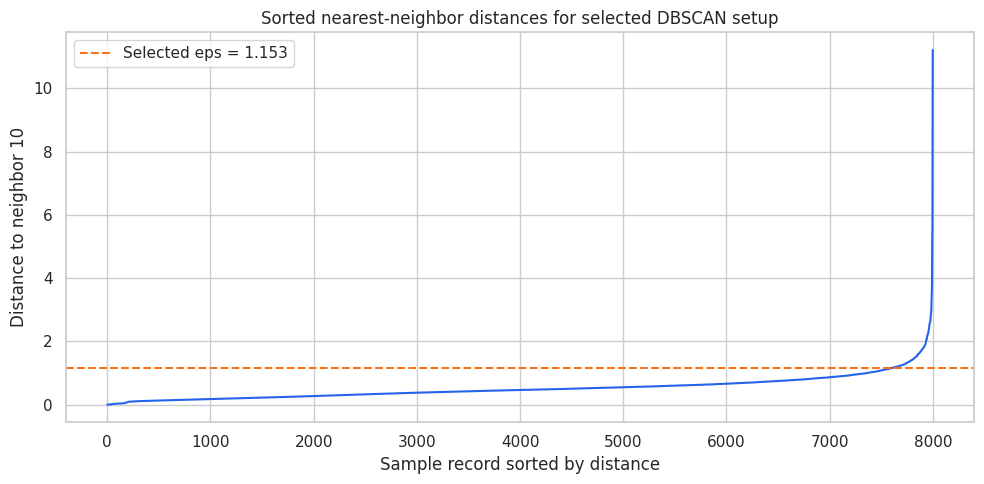

In [50]:
selected_distance_curve = dbscan_distance_curves[
    (SELECTED_DBSCAN_REPRESENTATION, SELECTED_DBSCAN_MIN_SAMPLES)
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(selected_distance_curve, color="#2563EB")
ax.axhline(
    SELECTED_DBSCAN_EPS,
    color="#F97316",
    linestyle="--",
    label=f"Selected eps = {SELECTED_DBSCAN_EPS:.3f}",
)
ax.set_title("Sorted nearest-neighbor distances for selected DBSCAN setup")
ax.set_xlabel("Sample record sorted by distance")
ax.set_ylabel(f"Distance to neighbor {SELECTED_DBSCAN_MIN_SAMPLES}")
ax.legend()
plt.tight_layout()
plt.show()

## 19. Check DBSCAN parameter sensitivity

DBSCAN can be sensitive to small parameter changes. The selected configuration is compared with nearby eps and min_samples values on the same records. Adjusted Rand Index includes the noise label and measures assignment agreement with the selected result.

In [51]:
EPS_MULTIPLIERS = [0.95, 1.00, 1.05]
MIN_SAMPLES_MULTIPLIERS = [0.75, 1.00, 1.25]
dbscan_sensitivity_rows = []

for eps_multiplier in EPS_MULTIPLIERS:
    for min_samples_multiplier in MIN_SAMPLES_MULTIPLIERS:
        candidate_eps = SELECTED_DBSCAN_EPS * eps_multiplier
        candidate_min_samples = max(
            2,
            int(round(SELECTED_DBSCAN_MIN_SAMPLES * min_samples_multiplier)),
        )
        sensitivity_model = DBSCAN(
            eps=candidate_eps,
            min_samples=candidate_min_samples,
            metric="euclidean",
            n_jobs=-1,
        )
        sensitivity_labels = sensitivity_model.fit_predict(selected_dbscan_values)
        sensitivity_cluster_count = len(
            set(int(label) for label in sensitivity_labels if label != -1)
        )
        dbscan_sensitivity_rows.append(
            {
                "eps_multiplier": eps_multiplier,
                "eps": candidate_eps,
                "min_samples": candidate_min_samples,
                "clusters": sensitivity_cluster_count,
                "noise_share": float((sensitivity_labels == -1).mean()),
                "adjusted_rand_index": adjusted_rand_score(
                    selected_dbscan_labels,
                    sensitivity_labels,
                ),
            }
        )

dbscan_sensitivity = pd.DataFrame(dbscan_sensitivity_rows)
display(dbscan_sensitivity)

,eps_multiplier,eps,min_samples,clusters,noise_share,adjusted_rand_index
0,0.95,1.094947,8,2,0.021000,0.898860
1,0.95,1.094947,10,1,0.025500,0.890440
2,0.95,1.094947,12,1,0.028750,0.827377
3,1.00,1.152576,8,2,0.016875,0.945569
4,1.00,1.152576,10,1,0.020750,1.000000
5,1.00,1.152576,12,1,0.023625,0.930941
6,1.05,1.210205,8,2,0.013750,0.851350
7,1.05,1.210205,10,2,0.015875,0.898559
8,1.05,1.210205,12,1,0.019250,0.947005


## 20. Profile DBSCAN groups and compare with K-Means

Noise means low local density under the selected parameters. It is not proof of fraud, error, or harmful behavior. Profiles use original units, and historical default rate is added only after DBSCAN fitting.

In [52]:
dbscan_profile_data = X_train.iloc[dbscan_sample_indices].loc[
    :, BEHAVIORAL_FEATURES
].reset_index(drop=True)
dbscan_profile_data["average_bill"] = dbscan_profile_data[BILL_FEATURES].mean(axis=1)
dbscan_profile_data["average_previous_payment"] = dbscan_profile_data[
    PAYMENT_FEATURES
].mean(axis=1)
dbscan_profile_data["average_repayment_status"] = dbscan_profile_data[
    REPAYMENT_FEATURES
].mean(axis=1)
dbscan_profile_data["average_bill_to_limit"] = (
    dbscan_profile_data["average_bill"]
    / dbscan_profile_data["credit_limit"]
)
dbscan_profile_data["historical_default"] = y_train.iloc[
    dbscan_sample_indices
].to_numpy()

if selected_dbscan_cluster_count == 1:
    density_group = np.where(selected_dbscan_labels == -1, "Noise", "Core")
else:
    density_group = np.where(
        selected_dbscan_labels == -1,
        "Noise",
        np.char.add("Cluster ", selected_dbscan_labels.astype(str)),
    )
dbscan_profile_data["density_group"] = density_group

dbscan_profiles = dbscan_profile_data.groupby("density_group")[
    PROFILE_FEATURES
].median()
dbscan_group_sizes = dbscan_profile_data["density_group"].value_counts()
dbscan_default_rates = dbscan_profile_data.groupby("density_group")[
    "historical_default"
].mean()
dbscan_profiles.insert(0, "records", dbscan_group_sizes)
dbscan_profiles.insert(1, "share", dbscan_group_sizes / len(dbscan_profile_data))
dbscan_profiles.insert(2, "historical_default_rate", dbscan_default_rates)
display(
    dbscan_profiles.style.format(
        {
            "share": "{:.2%}",
            "historical_default_rate": "{:.2%}",
            "credit_limit": "{:,.0f}",
            "average_bill": "{:,.0f}",
            "average_previous_payment": "{:,.0f}",
            "average_repayment_status": "{:.2f}",
            "average_bill_to_limit": "{:.2f}",
        }
    )
)

,records,share,historical_default_rate,credit_limit,average_bill,average_previous_payment,average_repayment_status,average_bill_to_limit
density_group,,,,,,,,
Core,7834,97.92%,22.06%,"140,000","19,830","2,367",0.00,0.27
Noise,166,2.08%,34.94%,"250,000","82,599","9,292",0.33,0.46


In [53]:
kmeans_sample_labels = selected_cluster_labels[dbscan_sample_indices]
if selected_dbscan_cluster_count >= 2:
    dbscan_non_noise_mask = selected_dbscan_labels != -1
    kmeans_dbscan_ari = adjusted_rand_score(
        kmeans_sample_labels[dbscan_non_noise_mask],
        selected_dbscan_labels[dbscan_non_noise_mask],
    )
else:
    kmeans_dbscan_ari = np.nan

clustering_comparison = pd.DataFrame(
    {
        "K-Means": {
            "records analyzed": len(X_train),
            "clusters": SELECTED_CLUSTER_COUNT,
            "noise share": 0.0,
            "supports prediction for new rows": True,
        },
        "DBSCAN": {
            "records analyzed": DBSCAN_SAMPLE_SIZE,
            "clusters": selected_dbscan_cluster_count,
            "noise share": selected_dbscan_noise_share,
            "supports prediction for new rows": False,
        },
    }
).T
display(clustering_comparison)
print(f"K-Means versus DBSCAN non-noise ARI: {kmeans_dbscan_ari}")

,records analyzed,clusters,noise share,supports prediction for new rows
K-Means,24000,2,0.0,True
DBSCAN,8000,1,0.02075,False


K-Means versus DBSCAN non-noise ARI: nan


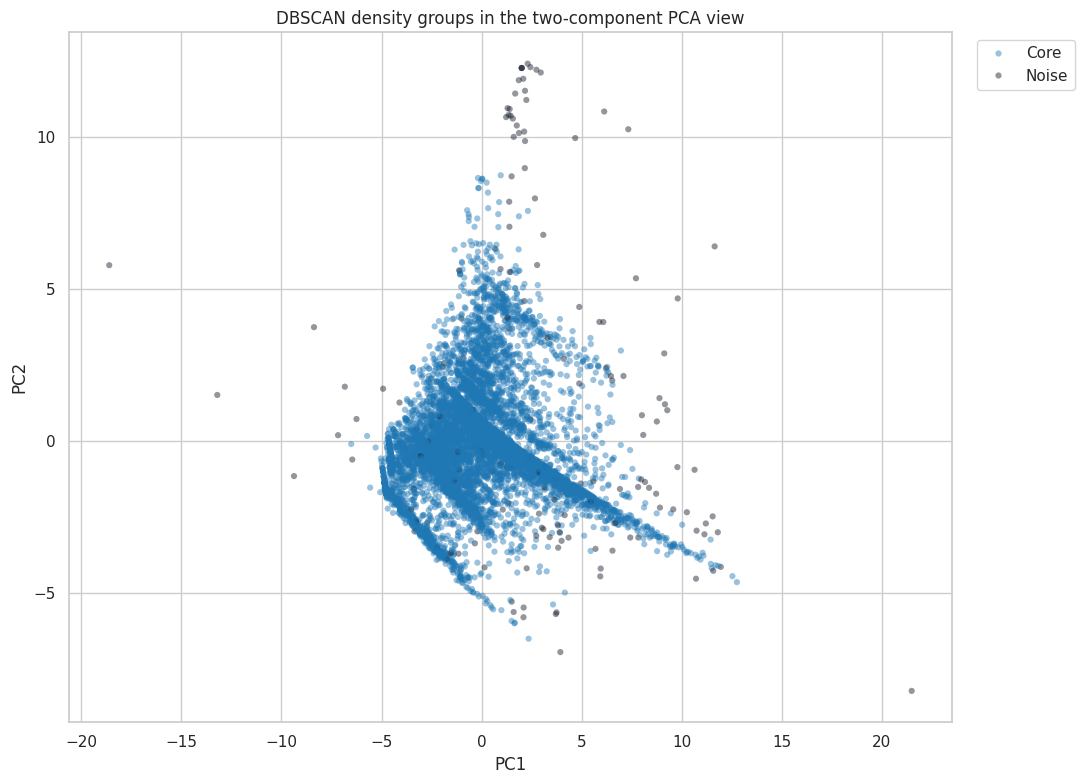

In [54]:
dbscan_plot = pd.DataFrame(
    {
        "PC1": X_train_pca_2d[dbscan_sample_indices, 0],
        "PC2": X_train_pca_2d[dbscan_sample_indices, 1],
        "density group": density_group,
    }
)
group_order = sorted(
    [group for group in dbscan_plot["density group"].unique() if group != "Noise"]
)
if "Noise" in set(dbscan_plot["density group"]):
    group_order.append("Noise")
palette_values = sns.color_palette("tab10", n_colors=max(1, len(group_order) - 1))
density_palette = {
    group: palette_values[index]
    for index, group in enumerate(group_order)
    if group != "Noise"
}
density_palette["Noise"] = "#111827"

fig, ax = plt.subplots(figsize=(11, 8))
sns.scatterplot(
    data=dbscan_plot,
    x="PC1",
    y="PC2",
    hue="density group",
    hue_order=group_order,
    palette=density_palette,
    alpha=0.45,
    s=20,
    linewidth=0,
    ax=ax,
)
ax.set_title("DBSCAN density groups in the two-component PCA view")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 21. Export DBSCAN analysis artifacts

Scikit-learn DBSCAN does not provide a standard predict method. These artifacts reproduce the fitted analysis and noise assignments, but they must not be exposed as a normal online prediction endpoint.

In [55]:
train_ids = ids.iloc[train_indices].reset_index(drop=True)
dbscan_assignments = train_ids.iloc[dbscan_sample_indices].reset_index(drop=True)
dbscan_assignments["dbscan_label"] = selected_dbscan_labels
dbscan_assignments["is_noise"] = selected_dbscan_labels == -1

dbscan_bundle = {
    "preprocessor": selected_preprocessor,
    "pca": selected_dbscan_reducer,
    "model": selected_dbscan,
    "input_features": BEHAVIORAL_FEATURES,
    "sample_indices": dbscan_sample_indices,
    "mode": DBSCAN_MODE,
}
joblib.dump(dbscan_bundle, output_directory / "dbscan_analysis_bundle.joblib")
dbscan_evaluation.to_csv(output_directory / "dbscan_evaluation.csv", index=False)
dbscan_sensitivity.to_csv(output_directory / "dbscan_sensitivity.csv", index=False)
dbscan_profiles.to_csv(output_directory / "dbscan_profiles.csv")
dbscan_assignments.to_csv(output_directory / "dbscan_assignments.csv", index=False)

dbscan_metadata = {
    "mode": DBSCAN_MODE,
    "representation": SELECTED_DBSCAN_REPRESENTATION,
    "sample_rows": DBSCAN_SAMPLE_SIZE,
    "eps": SELECTED_DBSCAN_EPS,
    "min_samples": SELECTED_DBSCAN_MIN_SAMPLES,
    "clusters": selected_dbscan_cluster_count,
    "noise_share": selected_dbscan_noise_share,
    "supports_new_row_prediction": False,
    "status": "exploratory",
}
with (output_directory / "dbscan_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(dbscan_metadata, file, indent=2)

print("DBSCAN analysis artifacts created in the Kaggle Output directory.")

DBSCAN analysis artifacts created in the Kaggle Output directory.


## 22. Unsupervised modeling conclusions

Current decisions:

- The identifier is excluded from all models.
- The target is excluded from PCA and clustering inputs.
- The initial behavioral models exclude demographic features.
- K-Means provides complete segment assignments and supports later assignment of new rows.
- DBSCAN is evaluated on a fixed training sample for predictable memory use.
- Tiny DBSCAN fragments are not presented as meaningful customer segments.
- DBSCAN noise means unusual local density, not confirmed fraud or error.
- DBSCAN does not provide standard prediction for new rows.
- The final supervised test split remains untouched.

The next section audits the three-way split and trains the feature-engineered gradient-boosting classifier using training-only cross-validation, validation-only threshold selection, and final holdout evaluation.

## 23. Audit split independence and diversity

The fixed split contains 24,000 training rows, 3,000 validation rows, and 3,000 final test rows. Both split operations shuffle customer positions with random state 42 and stratify on the target, so all partitions retain approximately the 22.12% default rate. Identifiers are never used as features.

Candidate selection and calibration use only the 24,000 training rows. The probability threshold is selected on the 3,000 validation rows, and the final 3,000-row test partition remains outside all model and threshold decisions.

In [56]:
X_v2_train_raw = X_train.copy()
y_v2_train = y_train.copy()
X_v2_validation_raw = X_validation.copy()
y_v2_validation = y_validation.copy()

supervised_v2_split_manifest = split_manifest.copy()
supervised_v2_split_manifest["target"] = y.to_numpy()

split_summary = pd.DataFrame(
    [
        {
            "partition": "training",
            "rows": len(X_v2_train_raw),
            "share": len(X_v2_train_raw) / len(X),
            "default_count": int(y_v2_train.sum()),
            "default_rate": float(y_v2_train.mean()),
        },
        {
            "partition": "validation",
            "rows": len(X_v2_validation_raw),
            "share": len(X_v2_validation_raw) / len(X),
            "default_count": int(y_v2_validation.sum()),
            "default_rate": float(y_v2_validation.mean()),
        },
        {
            "partition": "test",
            "rows": len(X_test),
            "share": len(X_test) / len(X),
            "default_count": int(y_test.sum()),
            "default_rate": float(y_test.mean()),
        },
    ]
).set_index("partition")
display(split_summary.style.format({"share": "{:.1%}", "default_rate": "{:.2%}"}))

partition_id_sets = {
    "training": set(ids.iloc[train_indices, 0]),
    "validation": set(ids.iloc[validation_indices, 0]),
    "test": set(ids.iloc[test_indices, 0]),
}
identifier_overlap_rows = []
for left_partition, right_partition in [
    ("training", "validation"),
    ("training", "test"),
    ("validation", "test"),
]:
    identifier_overlap_rows.append(
        {
            "comparison": f"{left_partition}_vs_{right_partition}",
            "identifier_overlap": len(
                partition_id_sets[left_partition]
                & partition_id_sets[right_partition]
            ),
        }
    )
identifier_overlap_audit = pd.DataFrame(identifier_overlap_rows)
identifier_overlap = int(identifier_overlap_audit["identifier_overlap"].sum())

partition_feature_frames = {
    "training": X_v2_train_raw,
    "validation": X_v2_validation_raw,
    "test": X_test,
}
distribution_rows = []
for left_partition, right_partition in [
    ("training", "validation"),
    ("training", "test"),
    ("validation", "test"),
]:
    for feature_name in X.columns:
        left_values = partition_feature_frames[left_partition][
            feature_name
        ].astype(float)
        right_values = partition_feature_frames[right_partition][
            feature_name
        ].astype(float)
        pooled_standard_deviation = np.sqrt(
            (left_values.var(ddof=1) + right_values.var(ddof=1)) / 2
        )
        absolute_smd = (
            abs(left_values.mean() - right_values.mean())
            / pooled_standard_deviation
            if pooled_standard_deviation
            else 0.0
        )
        distribution_rows.append(
            {
                "comparison": f"{left_partition}_vs_{right_partition}",
                "feature": feature_name,
                "absolute_standardized_mean_difference": absolute_smd,
            }
        )
split_distribution_audit = pd.DataFrame(distribution_rows).sort_values(
    "absolute_standardized_mean_difference", ascending=False
)

development_hashes = pd.util.hash_pandas_object(X_development, index=False)
test_hashes = pd.util.hash_pandas_object(X_test, index=False)
shared_profile_hashes = set(development_hashes) & set(test_hashes)
profiles_with_conflicting_targets = int(
    X.assign(default_next_month=y)
    .groupby(list(X.columns), dropna=False)["default_next_month"]
    .nunique()
    .gt(1)
    .sum()
)
split_audit_summary = pd.Series(
    {
        "identifier overlap": identifier_overlap,
        "test rows with a feature profile also present in development": int(
            test_hashes.isin(shared_profile_hashes).sum()
        ),
        "feature profiles with conflicting target labels": profiles_with_conflicting_targets,
        "maximum absolute standardized mean difference": float(
            split_distribution_audit[
                "absolute_standardized_mean_difference"
            ].max()
        ),
    },
    name="value",
)
display(split_audit_summary.to_frame())
display(identifier_overlap_audit)
display(split_distribution_audit.head(10))

,rows,share,default_count,default_rate
partition,,,,
training,24000,80.0%,5308,22.12%
validation,3000,10.0%,664,22.13%
test,3000,10.0%,664,22.13%


,value
identifier overlap,0.000000
test rows with a feature profile also present in development,10.000000
feature profiles with conflicting target labels,21.000000
maximum absolute standardized mean difference,0.074226


,comparison,identifier_overlap
0,training_vs_validation,0
1,training_vs_test,0
2,validation_vs_test,0


,comparison,feature,absolute_standardized_mean_difference
48,validation_vs_test,education,0.074226
56,validation_vs_test,repayment_status_apr,0.073263
55,validation_vs_test,repayment_status_may,0.067959
2,training_vs_validation,education,0.064778
9,training_vs_validation,repayment_status_may,0.056764
10,training_vs_validation,repayment_status_apr,0.054388
52,validation_vs_test,repayment_status_aug,0.053493
51,validation_vs_test,repayment_status_sep,0.049896
54,validation_vs_test,repayment_status_jun,0.049283
7,training_vs_validation,repayment_status_jul,0.047143


In [57]:
audit_age_bins = [0, 29, 39, 49, 59, np.inf]
audit_age_labels = ["under_30", "30_to_39", "40_to_49", "50_to_59", "60_plus"]
age_diversity_rows = []
for partition_name, partition_features, partition_target in [
    ("training", X_v2_train_raw, y_v2_train),
    ("validation", X_v2_validation_raw, y_v2_validation),
    ("test", X_test, y_test),
]:
    age_groups = pd.cut(
        partition_features["age"],
        bins=audit_age_bins,
        labels=audit_age_labels,
        include_lowest=True,
    )
    age_frame = pd.DataFrame(
        {
            "age_group": age_groups.astype(str).to_numpy(),
            "target": partition_target.to_numpy(),
        }
    )
    grouped_age = age_frame.groupby("age_group")["target"].agg(
        records="size", defaults="sum", default_rate="mean"
    )
    grouped_age.insert(0, "partition", partition_name)
    age_diversity_rows.append(grouped_age.reset_index())

age_diversity = pd.concat(age_diversity_rows, ignore_index=True)
display(
    age_diversity.sort_values(["age_group", "partition"]).style.format(
        {"default_rate": "{:.2%}"}
    )
)

audit_categorical_features = [
    "sex", "education", "marriage", *REPAYMENT_FEATURES
]
categorical_diversity_rows = []
for feature_name in audit_categorical_features:
    reference_codes = set(X[feature_name].unique())
    for partition_name, partition_features in partition_feature_frames.items():
        observed_codes = set(partition_features[feature_name].unique())
        missing_codes = sorted(reference_codes - observed_codes)
        categorical_diversity_rows.append(
            {
                "feature": feature_name,
                "partition": partition_name,
                "observed_code_count": len(observed_codes),
                "dataset_code_count": len(reference_codes),
                "missing_codes": (
                    ", ".join(str(int(code)) for code in missing_codes)
                    if missing_codes
                    else "none"
                ),
            }
        )
categorical_diversity = pd.DataFrame(categorical_diversity_rows)
display(categorical_diversity)

demographic_class_coverage_rows = []
for feature_name in ["sex", "education", "marriage"]:
    reference_pairs = set(zip(X[feature_name], y))
    for partition_name, partition_features, partition_target in [
        ("training", X_v2_train_raw, y_v2_train),
        ("validation", X_v2_validation_raw, y_v2_validation),
        ("test", X_test, y_test),
    ]:
        observed_pairs = set(zip(partition_features[feature_name], partition_target))
        missing_pairs = sorted(reference_pairs - observed_pairs)
        demographic_class_coverage_rows.append(
            {
                "feature": feature_name,
                "partition": partition_name,
                "missing_code_target_pairs": (
                    ", ".join(
                        f"({int(code)}, {int(target)})"
                        for code, target in missing_pairs
                    )
                    if missing_pairs
                    else "none"
                ),
            }
        )
demographic_class_coverage = pd.DataFrame(
    demographic_class_coverage_rows
)
display(demographic_class_coverage)
print("Rows were shuffled before splitting, with target stratification and random state 42.")
print("No identifier appears in more than one training, validation, or test partition.")

,age_group,partition,records,defaults,default_rate
10,30_to_39,test,1088,213,19.58%
0,30_to_39,training,9001,1822,20.24%
5,30_to_39,validation,1149,241,20.97%
11,40_to_49,test,666,166,24.92%
1,40_to_49,training,5151,1171,22.73%
6,40_to_49,validation,647,148,22.87%
12,50_to_59,test,243,59,24.28%
2,50_to_59,training,1870,458,24.49%
7,50_to_59,validation,228,65,28.51%
13,60_plus,test,46,17,36.96%


,feature,partition,observed_code_count,dataset_code_count,missing_codes
0,sex,training,2,2,none
1,sex,validation,2,2,none
2,sex,test,2,2,none
3,education,training,7,7,none
4,education,validation,7,7,none
5,education,test,7,7,none
6,marriage,training,4,4,none
7,marriage,validation,4,4,none
8,marriage,test,4,4,none
9,repayment_status_sep,training,11,11,none


,feature,partition,missing_code_target_pairs
0,sex,training,none
1,sex,validation,none
2,sex,test,none
3,education,training,none
4,education,validation,none
5,education,test,"(5, 1)"
6,marriage,training,none
7,marriage,validation,"(0, 1)"
8,marriage,test,"(0, 1)"


Rows were shuffled before splitting, with target stratification and random state 42.
No identifier appears in more than one training, validation, or test partition.


## 24. Engineer behavioral features for supervised v2

The classifier keeps demographic variables excluded and derives repayment consistency, delinquency counts, bill trends, payment trends, credit utilization, and payment-to-bill ratios from the 19 behavioral inputs. Ratio clipping limits the influence of very small denominators and extreme records.

The same deterministic implementation is stored in the project Python package so FastAPI can reproduce the 54-feature training representation.

In [58]:
FEATURE_ENGINEERING_VERSION = "behavioral-v2"
FEATURE_MONTHS = ["sep", "aug", "jul", "jun", "may", "apr"]

def engineer_behavioral_features(frame):
    missing_features = sorted(set(BEHAVIORAL_FEATURES) - set(frame.columns))
    if missing_features:
        raise ValueError(f"Missing behavioral features: {missing_features}.")

    engineered = frame.loc[:, BEHAVIORAL_FEATURES].astype(float).copy()
    credit_limit = engineered["credit_limit"].clip(lower=1.0)
    bill_values = engineered.loc[:, BILL_FEATURES]
    payment_values = engineered.loc[:, PAYMENT_FEATURES]
    repayment_values = engineered.loc[:, REPAYMENT_FEATURES]

    for month, bill_feature, payment_feature in zip(
        FEATURE_MONTHS, BILL_FEATURES, PAYMENT_FEATURES
    ):
        engineered[f"bill_to_limit_{month}"] = (
            engineered[bill_feature] / credit_limit
        ).clip(-5.0, 5.0)
        engineered[f"payment_to_limit_{month}"] = (
            engineered[payment_feature] / credit_limit
        ).clip(0.0, 5.0)
        bill_denominator = engineered[bill_feature].abs().clip(lower=100.0)
        engineered[f"payment_to_bill_{month}"] = (
            engineered[payment_feature] / bill_denominator
        ).clip(0.0, 10.0)

    engineered["bill_mean"] = bill_values.mean(axis=1)
    engineered["bill_std"] = bill_values.std(axis=1)
    engineered["bill_range"] = bill_values.max(axis=1) - bill_values.min(axis=1)
    engineered["bill_recent_change"] = (
        engineered["bill_statement_sep"] - engineered["bill_statement_apr"]
    )
    engineered["mean_bill_to_limit"] = (
        bill_values.mean(axis=1) / credit_limit
    ).clip(-5.0, 5.0)
    engineered["max_bill_to_limit"] = (
        bill_values.max(axis=1) / credit_limit
    ).clip(-5.0, 5.0)

    engineered["payment_sum"] = payment_values.sum(axis=1)
    engineered["payment_mean"] = payment_values.mean(axis=1)
    engineered["payment_std"] = payment_values.std(axis=1)
    engineered["zero_payment_months"] = (payment_values <= 0).sum(axis=1)
    positive_bill_total = bill_values.clip(lower=0.0).sum(axis=1).clip(lower=100.0)
    engineered["total_payment_to_bill"] = (
        payment_values.sum(axis=1) / positive_bill_total
    ).clip(0.0, 10.0)

    engineered["repayment_mean"] = repayment_values.mean(axis=1)
    engineered["repayment_max"] = repayment_values.max(axis=1)
    engineered["repayment_recent_change"] = (
        engineered["repayment_status_sep"]
        - engineered["repayment_status_apr"]
    )
    engineered["delayed_months"] = (repayment_values > 0).sum(axis=1)
    engineered["serious_delay_months"] = (repayment_values >= 2).sum(axis=1)
    engineered["severe_delay_months"] = (repayment_values >= 3).sum(axis=1)

    if not np.isfinite(engineered.to_numpy()).all():
        raise ValueError("Engineered behavioral features contain non-finite values.")
    return engineered


X_v2_train = engineer_behavioral_features(X_v2_train_raw)
X_v2_validation = engineer_behavioral_features(X_v2_validation_raw)
ENGINEERED_FEATURE_NAMES = list(X_v2_train.columns)
assert X_v2_train.shape == (24_000, 54)
assert X_v2_validation.shape == (3_000, 54)
assert not set(ENGINEERED_FEATURE_NAMES) & set(DEMOGRAPHIC_FEATURES)

feature_engineering_summary = pd.Series(
    {
        "raw behavioral features": len(BEHAVIORAL_FEATURES),
        "engineered model features": len(ENGINEERED_FEATURE_NAMES),
        "training rows": len(X_v2_train),
        "validation rows": len(X_v2_validation),
        "non-finite values": int(
            (~np.isfinite(X_v2_train.to_numpy())).sum()
        ),
    },
    name="value",
)
display(feature_engineering_summary.to_frame())

,value
raw behavioral features,19
engineered model features,54
training rows,24000
validation rows,3000
non-finite values,0


## 25. Cross-validate the gradient-boosting classifier

Ten histogram gradient-boosting configurations are compared with three-fold stratified cross-validation on the 24,000 training rows. Fixed learning rates of 0.01, 0.03, 0.05, and 0.08 are tested with a 600-iteration upper bound. Selection uses PR-AUC, then ROC-AUC. Every candidate uses a 10% internal training-only early-stopping fraction, patience of 30 iterations, and tolerance of 1e-7. The validation and test partitions remain outside this search.

Boosting iterations are tree-building rounds rather than neural-network epochs. The estimator minimizes binary log loss through gradient-based tree updates and does not use an Adam or SGD optimizer. Scikit-learn histogram gradient boosting has no native learning-rate decay callback, so fixed learning rates are compared and early stopping limits unnecessary rounds.

In [59]:
v2_candidate_specs = [
    {"name": "hgb_lr0.01_leaf15", "learning_rate": 0.01, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.03_leaf15", "learning_rate": 0.03, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.05_leaf15", "learning_rate": 0.05, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.08_leaf15", "learning_rate": 0.08, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.03_leaf31", "learning_rate": 0.03, "max_iter": 600, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.05_leaf31", "learning_rate": 0.05, "max_iter": 600, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_lr0.08_leaf31", "learning_rate": 0.08, "max_iter": 600, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"name": "hgb_leaf15_min50", "learning_rate": 0.05, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 50, "l2_regularization": 1.0},
    {"name": "hgb_leaf15_l2_5", "learning_rate": 0.05, "max_iter": 600, "max_leaf_nodes": 15, "min_samples_leaf": 20, "l2_regularization": 5.0},
    {"name": "hgb_lr0.05_leaf7", "learning_rate": 0.05, "max_iter": 600, "max_leaf_nodes": 7, "min_samples_leaf": 20, "l2_regularization": 1.0},
]

HGB_EARLY_STOPPING = {
    "early_stopping": True,
    "validation_fraction": 0.10,
    "n_iter_no_change": 30,
    "tol": 1e-7,
    "scoring": "loss",
}

def build_v2_model(specification):
    model_arguments = {
        key: value
        for key, value in specification.items()
        if key != "name"
    }
    return HistGradientBoostingClassifier(
        **model_arguments,
        **HGB_EARLY_STOPPING,
        random_state=RANDOM_STATE,
    )


v2_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
v2_scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "f1_at_0.50": "f1",
}

In [60]:
v2_cv_rows = []
v2_search_started = perf_counter()
for candidate_number, specification in enumerate(v2_candidate_specs, start=1):
    candidate_started = perf_counter()
    cv_result = cross_validate(
        build_v2_model(specification),
        X_v2_train,
        y_v2_train,
        cv=v2_cv,
        scoring=v2_scoring,
        n_jobs=-1,
        error_score="raise",
    )
    row = {
        "candidate": specification["name"],
        "wall_seconds": perf_counter() - candidate_started,
    }
    for metric_name in v2_scoring:
        values = cv_result[f"test_{metric_name}"]
        row[f"cv_{metric_name}"] = float(np.mean(values))
        row[f"cv_{metric_name}_std"] = float(np.std(values))
    v2_cv_rows.append(row)
    print(
        f"{candidate_number:02d}/{len(v2_candidate_specs)} "
        f"{specification['name']}: "
        f"PR-AUC={row['cv_pr_auc']:.4f}, "
        f"ROC-AUC={row['cv_roc_auc']:.4f}"
    )

v2_search_seconds = perf_counter() - v2_search_started
v2_cv_results = pd.DataFrame(v2_cv_rows).sort_values(
    ["cv_pr_auc", "cv_roc_auc"], ascending=False
).reset_index(drop=True)
selected_v2_row = v2_cv_results.iloc[0]
selected_v2_spec = next(
    specification
    for specification in v2_candidate_specs
    if specification["name"] == selected_v2_row["candidate"]
)
display(v2_cv_results)
print(f"Selected v2 candidate: {selected_v2_spec['name']}")
print(f"Total v2 search time: {v2_search_seconds:.1f} seconds")
print("Validation and test rows have not influenced candidate selection.")

01/10 hgb_lr0.01_leaf15: PR-AUC=0.5624, ROC-AUC=0.7839
02/10 hgb_lr0.03_leaf15: PR-AUC=0.5622, ROC-AUC=0.7838
03/10 hgb_lr0.05_leaf15: PR-AUC=0.5626, ROC-AUC=0.7835
04/10 hgb_lr0.08_leaf15: PR-AUC=0.5584, ROC-AUC=0.7817
05/10 hgb_lr0.03_leaf31: PR-AUC=0.5601, ROC-AUC=0.7819
06/10 hgb_lr0.05_leaf31: PR-AUC=0.5579, ROC-AUC=0.7815
07/10 hgb_lr0.08_leaf31: PR-AUC=0.5567, ROC-AUC=0.7806
08/10 hgb_leaf15_min50: PR-AUC=0.5620, ROC-AUC=0.7841
09/10 hgb_leaf15_l2_5: PR-AUC=0.5607, ROC-AUC=0.7835
10/10 hgb_lr0.05_leaf7: PR-AUC=0.5603, ROC-AUC=0.7824


,candidate,wall_seconds,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_roc_auc_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_f1_at_0.50,cv_f1_at_0.50_std
0,hgb_lr0.05_leaf15,1.717141,0.562560,0.011850,0.783540,0.005103,0.656140,0.002700,0.471123,0.005608
1,hgb_lr0.01_leaf15,8.508733,0.562416,0.012655,0.783936,0.005040,0.656487,0.003415,0.471918,0.007125
2,hgb_lr0.03_leaf15,2.942772,0.562156,0.011782,0.783776,0.004846,0.658076,0.003238,0.475051,0.006677
3,hgb_leaf15_min50,1.608363,0.562016,0.012740,0.784111,0.005304,0.657809,0.002901,0.474468,0.006167
4,hgb_leaf15_l2_5,2.025128,0.560730,0.012432,0.783522,0.005381,0.658709,0.002878,0.476262,0.005887
5,hgb_lr0.05_leaf7,2.478216,0.560347,0.010351,0.782375,0.003945,0.656774,0.001559,0.472341,0.003233
6,hgb_lr0.03_leaf31,3.076102,0.560087,0.012321,0.781893,0.004697,0.655212,0.004435,0.469243,0.009110
7,hgb_lr0.08_leaf15,1.700830,0.558372,0.011090,0.781746,0.004361,0.656911,0.003161,0.472526,0.006430
8,hgb_lr0.05_leaf31,2.153624,0.557893,0.013548,0.781519,0.005660,0.654812,0.003829,0.468382,0.007925
9,hgb_lr0.08_leaf31,1.426259,0.556717,0.014646,0.780586,0.006037,0.655321,0.003032,0.469516,0.006536


Selected v2 candidate: hgb_lr0.05_leaf15
Total v2 search time: 27.6 seconds
Validation and test rows have not influenced candidate selection.


## 26. Calibrate v2 and select its threshold on validation data

The frozen gradient-boosting configuration is calibrated with three-fold sigmoid calibration using only the 24,000 training rows. Each underlying estimator uses internal training-only early stopping. The 3,000-row validation set then selects the probability threshold that maximizes F1. The final test partition remains unused during all decisions.

In [61]:
def v2_metric_row(scenario, y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()
    return {
        "scenario": scenario,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


v2_calibration_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE
)
v2_validation_model = CalibratedClassifierCV(
    estimator=build_v2_model(selected_v2_spec),
    method="sigmoid",
    cv=v2_calibration_cv,
    n_jobs=-1,
)
v2_validation_fit_started = perf_counter()
v2_validation_model.fit(X_v2_train, y_v2_train)
v2_validation_fit_seconds = perf_counter() - v2_validation_fit_started
v2_validation_probabilities = v2_validation_model.predict_proba(
    X_v2_validation
)[:, 1]

v2_precision_curve, v2_recall_curve, v2_threshold_candidates = (
    precision_recall_curve(y_v2_validation, v2_validation_probabilities)
)
v2_f1_curve = (
    2 * v2_precision_curve[:-1] * v2_recall_curve[:-1]
    / np.maximum(
        v2_precision_curve[:-1] + v2_recall_curve[:-1],
        np.finfo(float).eps,
    )
)
v2_best_threshold_index = int(np.nanargmax(v2_f1_curve))
V2_PROBABILITY_THRESHOLD = float(
    v2_threshold_candidates[v2_best_threshold_index]
)
v2_validation_metrics = pd.DataFrame(
    [
        v2_metric_row(
            "validation_default_0.50",
            y_v2_validation,
            v2_validation_probabilities,
            0.50,
        ),
        v2_metric_row(
            "validation_selected_threshold",
            y_v2_validation,
            v2_validation_probabilities,
            V2_PROBABILITY_THRESHOLD,
        ),
    ]
).set_index("scenario")
display(v2_validation_metrics.style.format(precision=4))
print(f"Frozen v2 threshold: {V2_PROBABILITY_THRESHOLD:.4f}")
print("The final test set has not been used for v2 selection or threshold tuning.")

early_stopping_curve_rows = []
early_stopping_summary_rows = []
for fold_number, calibrated_classifier in enumerate(
    v2_validation_model.calibrated_classifiers_, start=1
):
    estimator = calibrated_classifier.estimator
    training_loss = -np.asarray(estimator.train_score_, dtype=float)
    internal_validation_loss = -np.asarray(
        estimator.validation_score_, dtype=float
    )
    best_iteration = int(np.argmin(internal_validation_loss))
    stopped_iteration = int(estimator.n_iter_)
    if stopped_iteration >= estimator.max_iter:
        diagnosis = "iteration cap reached; consider more rounds"
    elif internal_validation_loss[-1] > internal_validation_loss[best_iteration] + 1e-4:
        diagnosis = "validation loss plateaued; early stopping limited overfit"
    else:
        diagnosis = "validation loss remained stable at stopping"
    early_stopping_summary_rows.append(
        {
            "fold": fold_number,
            "best_iteration": best_iteration,
            "stopped_iteration": stopped_iteration,
            "best_training_loss": training_loss[best_iteration],
            "best_internal_validation_loss": internal_validation_loss[best_iteration],
            "train_validation_gap_at_best": (
                internal_validation_loss[best_iteration]
                - training_loss[best_iteration]
            ),
            "diagnosis": diagnosis,
        }
    )
    for iteration, (train_loss, validation_loss) in enumerate(
        zip(training_loss, internal_validation_loss)
    ):
        early_stopping_curve_rows.append(
            {
                "fold": fold_number,
                "iteration": iteration,
                "training_loss": train_loss,
                "internal_validation_loss": validation_loss,
            }
        )
v2_early_stopping_curves = pd.DataFrame(early_stopping_curve_rows)
v2_early_stopping_summary = pd.DataFrame(early_stopping_summary_rows)
display(v2_early_stopping_summary.style.format(precision=5))

,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier_score,log_loss,true_negative,false_positive,false_negative,true_positive
scenario,,,,,,,,,,,,,,,
validation_default_0.50,0.5000,0.8177,0.6555,0.6594,0.3645,0.9465,0.4694,0.7938,0.5592,0.1331,0.4229,2211,125,422,242
validation_selected_threshold,0.2916,0.8027,0.7272,0.5504,0.5919,0.8626,0.5704,0.7938,0.5592,0.1331,0.4229,2015,321,271,393


Frozen v2 threshold: 0.2916
The final test set has not been used for v2 selection or threshold tuning.


,fold,best_iteration,stopped_iteration,best_training_loss,best_internal_validation_loss,train_validation_gap_at_best,diagnosis
0,1,81,111,0.39997,0.41497,0.01500,validation loss plateaued; early stopping limited overfit
1,2,72,102,0.40082,0.42474,0.02392,validation loss plateaued; early stopping limited overfit
2,3,138,168,0.38518,0.44040,0.05522,validation loss plateaued; early stopping limited overfit


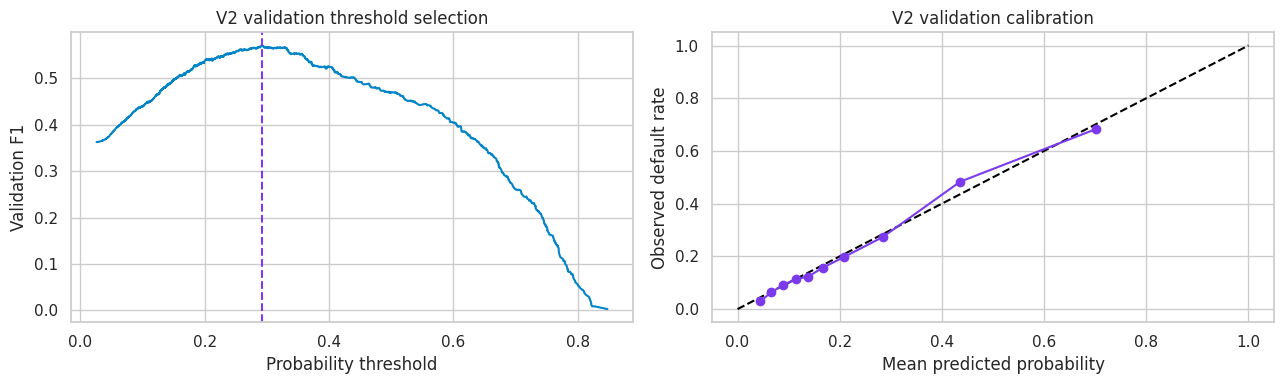

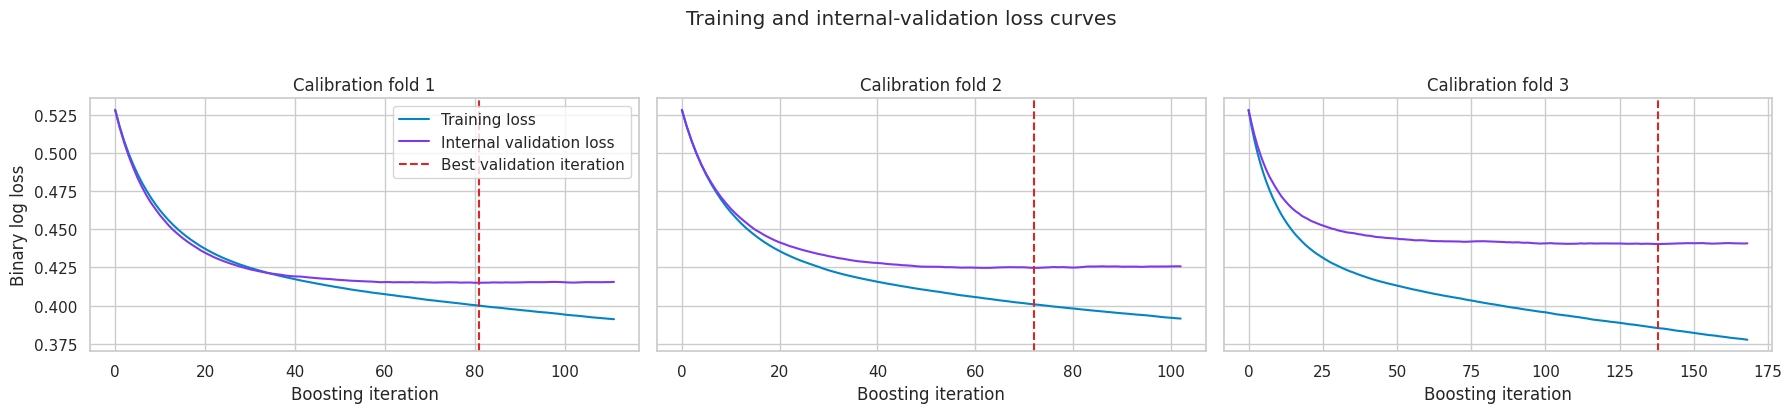

In [62]:
v2_observed_rate, v2_predicted_rate = calibration_curve(
    y_v2_validation,
    v2_validation_probabilities,
    n_bins=10,
    strategy="quantile",
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(v2_threshold_candidates, v2_f1_curve, color="#0284C7")
axes[0].axvline(V2_PROBABILITY_THRESHOLD, color="#7C3AED", linestyle="--")
axes[0].set(
    title="V2 validation threshold selection",
    xlabel="Probability threshold",
    ylabel="Validation F1",
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black")
axes[1].plot(v2_predicted_rate, v2_observed_rate, marker="o", color="#7C3AED")
axes[1].set(
    title="V2 validation calibration",
    xlabel="Mean predicted probability",
    ylabel="Observed default rate",
)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for fold_number, axis in enumerate(axes, start=1):
    fold_curve = v2_early_stopping_curves.loc[
        v2_early_stopping_curves["fold"] == fold_number
    ]
    fold_summary = v2_early_stopping_summary.loc[
        v2_early_stopping_summary["fold"] == fold_number
    ].iloc[0]
    axis.plot(
        fold_curve["iteration"],
        fold_curve["training_loss"],
        label="Training loss",
        color="#0284C7",
    )
    axis.plot(
        fold_curve["iteration"],
        fold_curve["internal_validation_loss"],
        label="Internal validation loss",
        color="#7C3AED",
    )
    axis.axvline(
        fold_summary["best_iteration"],
        color="#DC2626",
        linestyle="--",
        label="Best validation iteration",
    )
    axis.set(
        title=f"Calibration fold {fold_number}",
        xlabel="Boosting iteration",
    )
axes[0].set_ylabel("Binary log loss")
axes[0].legend()
fig.suptitle("Training and internal-validation loss curves", y=1.03)
plt.tight_layout()
plt.show()

## 27. Refit v2 and evaluate the fixed test set

After the candidate and threshold are frozen, the calibrated model is refit on all 27,000 development rows. The 3,000 test rows are transformed and evaluated once. Results at both the validation-selected threshold and 0.50 are retained so accuracy cannot hide missed defaults.

In [63]:
def measure_batch_latency(model, feature_frame, repeats=5):
    warmup_rows = min(32, len(feature_frame))
    model.predict_proba(feature_frame.iloc[:warmup_rows])
    durations_ms = []
    for _ in range(repeats):
        started = perf_counter()
        model.predict_proba(feature_frame)
        durations_ms.append((perf_counter() - started) * 1_000)
    return float(np.median(durations_ms))


X_v2_development = engineer_behavioral_features(X_development)
X_v2_test = engineer_behavioral_features(X_test)
assert list(X_v2_development.columns) == ENGINEERED_FEATURE_NAMES
assert list(X_v2_test.columns) == ENGINEERED_FEATURE_NAMES

v2_final_model = CalibratedClassifierCV(
    estimator=build_v2_model(selected_v2_spec),
    method="sigmoid",
    cv=v2_calibration_cv,
    n_jobs=-1,
)
v2_final_fit_started = perf_counter()
v2_final_model.fit(X_v2_development, y_development)
v2_final_fit_seconds = perf_counter() - v2_final_fit_started
v2_calibrated_iterations = [
    int(calibrated_classifier.estimator.n_iter_)
    for calibrated_classifier in v2_final_model.calibrated_classifiers_
]
v2_test_probabilities = v2_final_model.predict_proba(X_v2_test)[:, 1]
v2_test_predictions = (
    v2_test_probabilities >= V2_PROBABILITY_THRESHOLD
).astype("int8")
v2_batch_latency_ms = measure_batch_latency(v2_final_model, X_v2_test)

v2_holdout_metrics = pd.DataFrame(
    [
        v2_metric_row(
            "v2_default_0.50", y_test, v2_test_probabilities, 0.50
        ),
        v2_metric_row(
            "v2_validation_threshold",
            y_test,
            v2_test_probabilities,
            V2_PROBABILITY_THRESHOLD,
        ),
    ]
).set_index("scenario")
v2_holdout_metrics["fit_seconds"] = v2_final_fit_seconds
v2_holdout_metrics["batch_latency_ms"] = v2_batch_latency_ms
display(v2_holdout_metrics.style.format(precision=4))

v2_deployment_metrics = v2_holdout_metrics.loc["v2_validation_threshold"]
print(f"Selected learning rate: {selected_v2_spec['learning_rate']}")
print(f"Maximum boosting iterations: {selected_v2_spec['max_iter']}")
print(f"Actual calibrated-estimator iterations: {v2_calibrated_iterations}")

,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier_score,log_loss,true_negative,false_positive,false_negative,true_positive,fit_seconds,batch_latency_ms
scenario,,,,,,,,,,,,,,,,,
v2_default_0.50,0.5000,0.8247,0.6605,0.6983,0.3660,0.9551,0.4802,0.7877,0.5713,0.1323,0.4230,2231,105,421,243,1.7538,49.4169
v2_validation_threshold,0.2916,0.8047,0.7102,0.5609,0.5407,0.8797,0.5506,0.7877,0.5713,0.1323,0.4230,2055,281,305,359,1.7538,49.4169


Selected learning rate: 0.05
Maximum boosting iterations: 600
Actual calibrated-estimator iterations: [116, 131, 106]


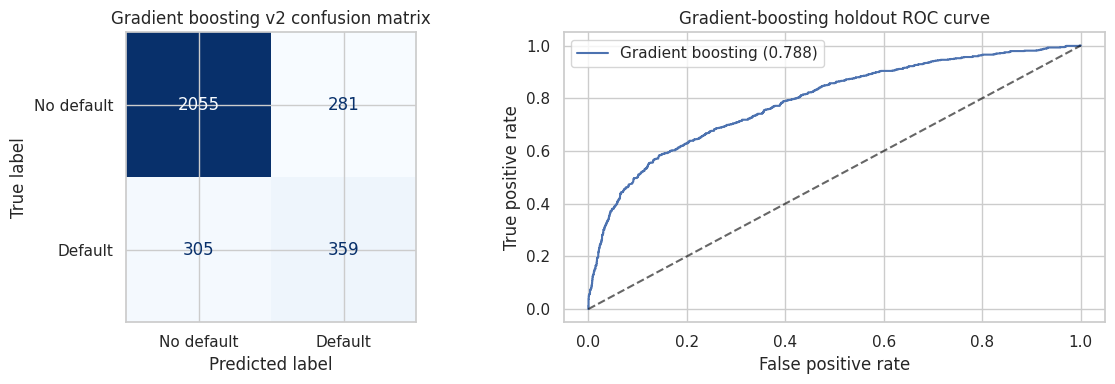

,attribute,group,records,historical_default_rate,mean_predicted_probability,positive_prediction_rate,recall,false_positive_rate,precision
0,sex_group,female_code_2,1782,21.32%,21.14%,19.70%,52.11%,10.91%,56.41%
1,sex_group,male_code_1,1218,23.32%,22.71%,23.73%,56.69%,13.70%,55.71%
2,age_group,under_30,957,21.84%,23.29%,23.09%,57.89%,13.37%,54.75%
3,age_group,30_to_39,1088,19.58%,19.71%,18.75%,48.83%,11.43%,50.98%
4,age_group,40_to_49,666,24.92%,22.04%,21.92%,56.02%,10.60%,63.70%
5,age_group,50_to_59,243,24.28%,24.07%,24.28%,57.63%,13.59%,57.63%


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    v2_test_predictions,
    labels=[0, 1],
    display_labels=["No default", "Default"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Gradient boosting v2 confusion matrix")
v2_fpr, v2_tpr, _ = roc_curve(y_test, v2_test_probabilities)
axes[1].plot(
    v2_fpr,
    v2_tpr,
    label=f"Gradient boosting ({roc_auc_score(y_test, v2_test_probabilities):.3f})",
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black", alpha=0.6)
axes[1].set(
    title="Gradient-boosting holdout ROC curve",
    xlabel="False positive rate",
    ylabel="True positive rate",
)
axes[1].legend()
plt.tight_layout()
plt.show()

def calculate_subgroup_metrics(frame, attribute, minimum_records=50):
    rows = []
    for group_name, group_frame in frame.groupby(
        attribute, observed=False, dropna=False
    ):
        if len(group_frame) < minimum_records:
            continue
        tn, fp, fn, tp = confusion_matrix(
            group_frame["actual"],
            group_frame["predicted"],
            labels=[0, 1],
        ).ravel()
        rows.append(
            {
                "attribute": attribute,
                "group": str(group_name),
                "records": len(group_frame),
                "historical_default_rate": group_frame["actual"].mean(),
                "mean_predicted_probability": group_frame["probability"].mean(),
                "positive_prediction_rate": group_frame["predicted"].mean(),
                "recall": tp / (tp + fn) if tp + fn else np.nan,
                "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan,
                "precision": tp / (tp + fp) if tp + fp else np.nan,
            }
        )
    return rows


v2_subgroup_frame = X_test.loc[:, DEMOGRAPHIC_FEATURES].copy()
v2_subgroup_frame["actual"] = y_test.to_numpy()
v2_subgroup_frame["predicted"] = v2_test_predictions
v2_subgroup_frame["probability"] = v2_test_probabilities
v2_subgroup_frame["sex_group"] = v2_subgroup_frame["sex"].map(
    {1: "male_code_1", 2: "female_code_2"}
).fillna("undocumented_code")
v2_subgroup_frame["age_group"] = pd.cut(
    v2_subgroup_frame["age"],
    bins=audit_age_bins,
    labels=audit_age_labels,
    include_lowest=True,
)
v2_subgroup_metrics = pd.DataFrame(
    calculate_subgroup_metrics(v2_subgroup_frame, "sex_group")
    + calculate_subgroup_metrics(v2_subgroup_frame, "age_group")
)
display(
    v2_subgroup_metrics.style.format(
        {
            "historical_default_rate": "{:.2%}",
            "mean_predicted_probability": "{:.2%}",
            "positive_prediction_rate": "{:.2%}",
            "recall": "{:.2%}",
            "false_positive_rate": "{:.2%}",
            "precision": "{:.2%}",
        }
    )
)

## 28. Export the v2 classifier and audit artifacts

The v2 model consumes the deterministic 54-feature representation. The FastAPI layer must call the versioned project feature-engineering function before inference. The bundle records the raw input order, engineered feature order, calibration model, validation-selected threshold, early-stopping configuration, actual boosting iterations, and model version. The serialized joblib bundle is the retained best selected model artifact; scikit-learn does not create a separate checkpoint after every boosting iteration.

In [65]:
v2_bundle = {
    "model": v2_final_model,
    "raw_input_features": BEHAVIORAL_FEATURES,
    "engineered_feature_names": ENGINEERED_FEATURE_NAMES,
    "feature_engineering_version": FEATURE_ENGINEERING_VERSION,
    "selected_candidate": selected_v2_spec,
    "training_objective": "binary log loss",
    "optimizer": "gradient-based tree boosting; no neural-network optimizer",
    "early_stopping": HGB_EARLY_STOPPING,
    "best_validation_iterations": (
        v2_early_stopping_summary["best_iteration"].astype(int).tolist()
    ),
    "actual_calibrated_estimator_iterations": v2_calibrated_iterations,
    "probability_threshold": V2_PROBABILITY_THRESHOLD,
    "positive_class": 1,
    "model_version": "credit-risk-v2",
}
v2_artifact_path = output_directory / "credit_risk_v2_bundle.joblib"
joblib.dump(v2_bundle, v2_artifact_path, compress=3)
split_summary.to_csv(output_directory / "supervised_v2_split_summary.csv")
supervised_v2_split_manifest.to_csv(
    output_directory / "supervised_v2_split_manifest.csv", index=False
)
split_distribution_audit.to_csv(
    output_directory / "supervised_v2_split_distribution_audit.csv", index=False
)
identifier_overlap_audit.to_csv(
    output_directory / "supervised_v2_identifier_overlap_audit.csv", index=False
)
age_diversity.to_csv(
    output_directory / "supervised_v2_age_diversity.csv", index=False
)
categorical_diversity.to_csv(
    output_directory / "supervised_v2_categorical_diversity.csv", index=False
)
demographic_class_coverage.to_csv(
    output_directory / "supervised_v2_demographic_class_coverage.csv", index=False
)
v2_cv_results.to_csv(output_directory / "supervised_v2_cv_results.csv", index=False)
v2_early_stopping_curves.to_csv(
    output_directory / "supervised_v2_loss_curves.csv", index=False
)
v2_early_stopping_summary.to_csv(
    output_directory / "supervised_v2_early_stopping_summary.csv", index=False
)
v2_validation_metrics.to_csv(output_directory / "supervised_v2_validation_metrics.csv")
v2_holdout_metrics.to_csv(output_directory / "supervised_v2_holdout_metrics.csv")
v2_subgroup_metrics.to_csv(output_directory / "supervised_v2_subgroup_metrics.csv", index=False)

v2_metadata = {
    "dataset_id": UCI_DATASET_ID,
    "random_state": RANDOM_STATE,
    "split_protocol": "80% training, 10% validation, 10% test",
    "split_rows": {
        "training": int(len(X_v2_train_raw)),
        "validation": int(len(X_v2_validation_raw)),
        "test": int(len(X_test)),
    },
    "split_audit": {
        "identifier_overlap": identifier_overlap,
        "maximum_absolute_standardized_mean_difference": float(
            split_distribution_audit[
                "absolute_standardized_mean_difference"
            ].max()
        ),
        "test_rows_sharing_a_development_feature_profile": int(
            test_hashes.isin(shared_profile_hashes).sum()
        ),
        "feature_profiles_with_conflicting_targets": (
            profiles_with_conflicting_targets
        ),
    },
    "feature_engineering_version": FEATURE_ENGINEERING_VERSION,
    "raw_feature_count": len(BEHAVIORAL_FEATURES),
    "engineered_feature_count": len(ENGINEERED_FEATURE_NAMES),
    "selected_candidate": selected_v2_spec,
    "training_objective": "binary log loss",
    "optimizer": "gradient-based tree boosting; no neural-network optimizer",
    "learning_rate_schedule": "fixed; candidates selected by cross-validation",
    "early_stopping": HGB_EARLY_STOPPING,
    "best_validation_iterations": (
        v2_early_stopping_summary["best_iteration"].astype(int).tolist()
    ),
    "actual_calibrated_estimator_iterations": v2_calibrated_iterations,
    "selection_metric": "three-fold training PR-AUC",
    "threshold_selection": "maximum F1 on the validation partition",
    "probability_threshold": V2_PROBABILITY_THRESHOLD,
    "holdout_metrics": {
        metric_name: float(v2_deployment_metrics[metric_name])
        for metric_name in [
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "log_loss",
        ]
    },
    "artifact_size_mb": v2_artifact_path.stat().st_size / (1024 ** 2),
    "scikit_learn_version": sklearn.__version__,
    "intended_use": "educational decision-support demonstration",
    "status": "provisional",
}
with (output_directory / "credit_risk_v2_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(v2_metadata, file, indent=2)

print(f"V2 artifact size: {v2_metadata['artifact_size_mb']:.2f} MB")
print("V2 model and aggregate audit artifacts created.")

V2 artifact size: 0.42 MB
V2 model and aggregate audit artifacts created.


## 29. Final project interpretation

The feature-engineered gradient-boosting classifier remains within scikit-learn for portable deployment. It does not approach 90% F1 because the available historical features do not perfectly determine future default.

The project demonstrates two important professional behaviors: choosing methods that match the learning objective and refusing to manufacture unrealistic metrics through leakage. Gradient boosting is the only supervised classifier retained in this notebook.

The next implementation phase will load the v2 bundle in FastAPI, reproduce behavioral-v2 feature engineering, validate synthetic requests, and expose calibrated probabilities with an explicit educational-use warning.